# KHÓA LUẬN TỐT NGHIỆP: GIAI ĐOẠN 2 (STAGE 2)
## HUẤN LUYỆN MODEL V2 TRÊN TẬP ĐỐI SÁNH (DUPLICATES + GÁN TỰ ĐỘNG STAGE 1) & ĐỐI SÁNH TRỰC DIỆN VỚI MODEL V1
---
### Mục Tiêu & Phương Pháp Luận Nghiên Cứu:
1. **Mục Tiêu Nghiên Cứu Cốt Lõi**:
   - Huấn luyện mô hình **Model V2** trên tập dữ liệu đối sánh (kết hợp **MyTrashNet_Duplicates** và các ảnh **MyTrashNet_Unique** đã được gán nhãn tự động từ Stage 1).
   - Kiểm định giả thuyết khoa học: *"Liệu mô hình học từ dữ liệu gán nhãn tự động (Model V2) có đạt hiệu năng tiệm cận với mô hình học từ 100% dữ liệu gán thủ công (Model V1) không?"*
2. **Nguyên Tắc BẢO VỆ TẬP TEST (Zero Data Leakage - Không Rò Rỉ Dữ Liệu)**:
   - Nạp file chuẩn **`test_set_chuan_10_percent.csv`** (được xuất từ Model V1 `kltn-convnext-tiny.ipynb`).
   - Lọc ra CHÍNH XÁC 10% ảnh test này (theo `filename`).
   - Nhãn của tập Test (`test_df['label']`) BẮT BUỘC lấy từ nhãn gốc trong file ảnh (**Ground Truth** trích xuất từ tên file), đóng vai trò là thước đo vàng (Gold Standard Benchmark) độc lập và khách quan.
   - **Loại bỏ hoàn toàn các ảnh test này ra khỏi tập huấn luyện / validation của Model V2**.
   - 90% dữ liệu còn lại được chia thành **Train (80% tổng thể)** và **Validation (10% tổng thể)** để huấn luyện Model V2.
3. **Huấn Luyện Model V2 (Hierarchical ConvNeXt-Tiny)**:
   - Kiến trúc đồng nhất với Model V1: Backbone ConvNeXt-Tiny, CosineDense Heads, Area Resampling ($320 \times 320$), MixUp/CutMix ($\alpha = 0.2$), Cosine Decay Schedule.
4. **Đánh Giá Đối Sánh Trực Diện V1 vs V2**:
   - Vận hành bộ lọc 5-View TTA + 2 Chốt chặn an toàn trên cùng 10% tập Test chuẩn.
   - Xuất bảng so sánh đối đầu trực diện giữa Model V1 (100% nhãn thủ công) và Model V2 (Dữ liệu gán tự động) trên mọi chỉ số: Accuracy, F1-Score từng lớp, Tỉ lệ gắp tự động an toàn, Số lỗi lọt lưới.


In [1]:
# CELL 1 === 1. KHỞI TẠO THƯ VIỆN & THIẾT LẬP CẤU HÌNH ===
import os
import gc
import sys
import glob
import time
import json
import random
from collections import defaultdict, Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy.special import softmax

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.models import Model
from tensorflow.keras.applications import ConvNeXtTiny
from tensorflow.keras.applications.convnext import preprocess_input as preprocess_convnext

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# Cấu hình GPU động
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f'✅ Đã phát hiện và kích hoạt {len(gpus)} GPU: {[g.name for g in gpus]}')
    except RuntimeError as e:
        print(f'⚠️ Cảnh báo GPU: {e}')
else:
    print('⚠️ Không tìm thấy GPU, hệ thống sẽ chạy trên CPU.')

# Thiết lập Seed cố định đảm bảo tính tái lập
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Siêu tham số chuẩn từ mytrashnet-convnext-retrain-tta-safety
IMG_SIZE = (320, 320)
BATCH_SIZE = 32
EPOCHS_STAGE1 = 15
EPOCHS_STAGE2 = 25
MIXUP_ALPHA = 0.2

STAGE1_CHECKPOINT = 'best_v2_convnext_stage1.keras'
STAGE2_CHECKPOINT = 'best_v2_convnext_retrained.keras'

print('✅ Đã thiết lập xong môi trường và siêu tham số cho Hierarchical ConvNeXt-Tiny!')

✅ Đã phát hiện và kích hoạt 2 GPU: ['/physical_device:GPU:0', '/physical_device:GPU:1']
✅ Đã thiết lập xong môi trường và siêu tham số cho Hierarchical ConvNeXt-Tiny!


In [2]:
# CELL 2 === 2. TẬP DỮ LIỆU ĐỐI SÁNH & NẠP TẬP TEST ĐỘC LẬP 10% (CHÍNH QUY 100%) ===
import glob
import os
import shutil
import zipfile
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

try:
  SEED
except NameError:
  SEED = 42

TARGET_CLASSES = ['glass', 'metal', 'paper', 'plastic']


def extract_ground_truth_label(filename, fallback_label=None):
  """Trích xuất nhãn thực tế chuẩn (Ground Truth) từ tên file ảnh."""
  fn = os.path.basename(str(filename)).lower()
  for c in TARGET_CLASSES:
    if fn.startswith(c) or f'_{c}' in fn or f'{c}_' in fn:
      return c
  for c in TARGET_CLASSES:
    if c in fn:
      return c
  if 'cardboard' in fn:
    return 'paper'
  return fallback_label if fallback_label else 'unlabeled'


def discover_path(candidates, target_name=None):
  """Tìm kiếm file hoặc thư mục theo danh sách ưu tiên."""
  for p in candidates:
    if p and os.path.exists(p):
      return p
  if target_name:
    target_clean = os.path.basename(target_name).lower()
    search_roots = ['/kaggle/input', '/kaggle/working', '.']
    for root in search_roots:
      if os.path.exists(root):
        for dirpath, dirnames, filenames in os.walk(root):
          for f in filenames:
            if f.lower() == target_clean:
              return os.path.join(dirpath, f)
          for d in dirnames:
            d_norm = d.lower().replace('-', '_')
            t_norm = target_clean.replace('-', '_')
            if d.lower() == target_clean or d_norm == t_norm or t_norm in d_norm:
              return os.path.join(dirpath, d)
  return None


def find_class_root(base_dir):
  """Tìm thư mục chứa trực tiếp 4 thư mục nhãn TARGET_CLASSES:

  ['glass', 'metal', 'paper', 'plastic'].
  """
  if not base_dir or not os.path.exists(base_dir):
    return None
  if all(os.path.isdir(os.path.join(base_dir, c)) for c in TARGET_CLASSES):
    return base_dir
  for root, dirs, _ in os.walk(base_dir):
    if all(c in dirs for c in TARGET_CLASSES):
      return root
  return None


# ==============================================================================
# BƯỚC 1: NẠP TẬP TEST ĐỘC LẬP 10% (CÔ LẬP HOÀN TOÀN TỪ ĐẦU - ZERO LEAKAGE)
# ==============================================================================
test_dir_candidates = [
    '/kaggle/input/datasets/vminhkhoi/test-10-percent/MyTrashNet_Test_10Percent',
    '/kaggle/input/test-10-percent/MyTrashNet_Test_10Percent',
    '/kaggle/input/datasets/vminhkhoi/test-10-percent',
    '/kaggle/input/test-10-percent',
    '/kaggle/input/datasets/vminhkhoi/mytrashnet-test-10percent/MyTrashNet_Test_10Percent',
    '/kaggle/input/mytrashnet-test-10percent/MyTrashNet_Test_10Percent',
    '/kaggle/input/datasets/vminhkhoi/mytrashnet-test-10percent',
    '/kaggle/input/mytrashnet-test-10percent',
    '/kaggle/input/MyTrashNet_Test_10Percent',
    'MyTrashNet_Test_10Percent',
    './MyTrashNet_Test_10Percent',
    '../MyTrashNet_Test_10Percent',
    'ConvNeXtTiny/MyTrashNet_Test_10Percent',
    'c:/Users/HP/Downloads/KLTN (code)/MyTrashNet_Test_10Percent',
]

dir_test_raw = discover_path(
    test_dir_candidates, target_name='MyTrashNet_Test_10Percent'
)
if not dir_test_raw:
  dir_test_raw = discover_path(test_dir_candidates, target_name='test-10-percent')

# Tự động giải nén nếu dữ liệu test ở dạng file .zip
if dir_test_raw and dir_test_raw.endswith('.zip'):
  extract_test_dir = '/kaggle/working/MyTrashNet_Test_10Percent'
  if not os.path.exists(extract_test_dir):
    print(f"📦 Đang giải nén tập Test: '{dir_test_raw}'...")
    os.makedirs(extract_test_dir, exist_ok=True)
    with zipfile.ZipFile(dir_test_raw, 'r') as zip_ref:
      zip_ref.extractall(extract_test_dir)
    print('✅ Giải nén tập Test thành công!')
  dir_test_raw = extract_test_dir

dir_test = find_class_root(dir_test_raw)
if dir_test is None:
  raise FileNotFoundError(
      "❌ Không tìm thấy thư mục tập Test độc lập 'MyTrashNet_Test_10Percent'"
      ' chứa 4 lớp!'
  )

print(f'🎯 Thư mục Tập Test độc lập (10% Benchmark): {dir_test}')

test_records = []
for c in TARGET_CLASSES:
  c_path = os.path.join(dir_test, c)
  if os.path.exists(c_path):
    for f in sorted(os.listdir(c_path)):
      if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')):
        test_records.append({
            'filepath': os.path.join(c_path, f),
            'filename': f,
            'label': c,
            'ground_truth': c,
        })

test_df = pd.DataFrame(test_records).reset_index(drop=True)
print(
    f'📖 Đã nạp thành công {len(test_df):,} ảnh thuộc tập Test Benchmark độc lập'
    ' (10% Gold Standard).'
)
for c in TARGET_CLASSES:
  cnt = len(test_df[test_df['label'] == c])
  print(f'   * Lớp Test [{c:8s}]: {cnt:4d} ảnh')

# ==============================================================================
# BƯỚC 2: KHÁM PHÁ & NẠP KHO DỮ LIỆU ĐỐI SÁNH STAGE 1 (DATASET_DOI_SANH)
# ==============================================================================
doi_sanh_candidates = [
    '/kaggle/input/datasets/vminhkhoi/dataset-doisanh',
    '/kaggle/input/dataset-doisanh',
    '/kaggle/input/dataset_doi_sanh',
    '/kaggle/input/datasets/vminhkhoi/dataset-doisanh/dataset_doi_sanh',
    '/kaggle/input/dataset-doisanh/dataset_doi_sanh',
    'dataset_doi_sanh',
    './dataset_doi_sanh',
    '/kaggle/working/dataset_doi_sanh',
]

dir_doi_sanh = discover_path(doi_sanh_candidates, target_name='dataset-doisanh')
if not dir_doi_sanh:
  dir_doi_sanh = discover_path(
      doi_sanh_candidates, target_name='dataset_doi_sanh'
  )

# Tự động giải nén nếu dữ liệu đối sánh là file .zip
if dir_doi_sanh and dir_doi_sanh.endswith('.zip'):
  extract_target = '/kaggle/working/dataset_doi_sanh'
  if not os.path.exists(extract_target):
    print(f"📦 Đang giải nén tập đối sánh: '{dir_doi_sanh}'...")
    os.makedirs(extract_target, exist_ok=True)
    with zipfile.ZipFile(dir_doi_sanh, 'r') as zip_ref:
      zip_ref.extractall(extract_target)
    print('✅ Giải nén tập đối sánh hoàn tất!')
  dir_doi_sanh = extract_target

class_root = find_class_root(dir_doi_sanh)
train_val_records = []

if class_root:
  print(
      '📁 Tìm thấy cấu trúc dữ liệu đối sánh hợp nhất tại:'
      f' {class_root}'
  )
  for c in TARGET_CLASSES:
    c_path = os.path.join(class_root, c)
    if os.path.exists(c_path):
      for f in sorted(os.listdir(c_path)):
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.webp')):
          train_val_records.append({
              'filepath': os.path.join(c_path, f),
              'filename': f,
              'label': c,
          })
else:
  raise FileNotFoundError(
      "❌ Không tìm thấy thư mục 'dataset_doi_sanh' chứa 4 lớp để huấn luyện"
      ' Model V2!'
  )

df_train_val = (
    pd.DataFrame(train_val_records)
    .drop_duplicates(subset=['filename'])
    .reset_index(drop=True)
)
print(
    '📊 Tổng số ảnh huấn luyện & xác thực (Train/Val Pool):'
    f' {len(df_train_val):,} ảnh'
)

# ==============================================================================
# BƯỚC 3: PHÂN CHIA TRAIN (80% TỔNG THỂ) VÀ VALIDATION (10% TỔNG THỂ)
# ==============================================================================
# Tập đối sánh sạch có ~7,254 ảnh (chiếm 90% tổng dữ liệu).
# Để đạt tỉ lệ chuẩn 80% Train và 10% Val của toàn bài toán: val_size = 1/9 ≈ 0.11111
train_df, val_df = train_test_split(
    df_train_val,
    test_size=(1.0 / 9.0),
    random_state=SEED,
    stratify=df_train_val['label'],
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

N_TOTAL = len(train_df) + len(val_df) + len(test_df)
print(
    '\n🎯 PHÂN CHIA DỮ LIỆU ĐỐI SÁNH CHÍNH QUY (Chuẩn hóa 80/10/10 trên'
    f' {N_TOTAL:,} ảnh):'
)
print(
    f' - Train      : {len(train_df):,} ảnh'
    f' ({len(train_df)/N_TOTAL*100:.1f}%) [Học từ Seed + Tự động + Thủ công]'
)
print(
    f' - Validation : {len(val_df):,} ảnh ({len(val_df)/N_TOTAL*100:.1f}%)'
)
print(
    f' - Test       : {len(test_df):,} ảnh ({len(test_df)/N_TOTAL*100:.1f}%)'
    ' [Nạp trực tiếp từ MyTrashNet_Test_10Percent]'
)

# ==============================================================================
# BƯỚC 4: KIỂM ĐỊNH AN TOÀN TUYỆT ĐỐI (ZERO DATA LEAKAGE)
# ==============================================================================
train_test_overlap = set(train_df['filename']).intersection(
    set(test_df['filename'])
)
val_test_overlap = set(val_df['filename']).intersection(
    set(test_df['filename'])
)

if len(train_test_overlap) == 0 and len(val_test_overlap) == 0:
  print(
      '🛡️ KIỂM ĐỊNH AN TOÀN: 0% RÒ RỈ DỮ LIỆU (Zero Data Leakage). Tập Test'
      ' hoàn toàn độc lập 100%!'
  )
else:
  raise ValueError(
      f'❌ CẢNH BÁO: Phát hiện {len(train_test_overlap)} ảnh Train và'
      f' {len(val_test_overlap)} ảnh Val trùng với Test!'
  )

# ==============================================================================
# BƯỚC 5: THIẾT LẬP BỘ ÁNH XẠ NHÃN & SIÊU LỚP
# ==============================================================================
sub_labels = sorted(TARGET_CLASSES)
num_sub_classes = len(sub_labels)
class_labels = sub_labels
sub_to_idx = {label: i for i, label in enumerate(sub_labels)}
idx_to_sub = {i: label for i, label in enumerate(sub_labels)}

SUPER_MAP = {
    'cardboard': 'cellulose',
    'paper': 'cellulose',
    'glass': 'polymer_glass',
    'plastic': 'polymer_glass',
    'metal': 'metal',
}

sub_to_super_name = {c: SUPER_MAP.get(c, c) for c in sub_labels}
super_labels = sorted(list(set(sub_to_super_name.values())))
num_super_classes = len(super_labels)
super_to_idx = {name: i for i, name in enumerate(super_labels)}
idx_to_super = {i: name for i, name in enumerate(super_labels)}
SUB_TO_SUPER = {
    sub_to_idx[c]: super_to_idx[sub_to_super_name[c]] for c in sub_labels
}

print(
    f'\n✅ Cấu hình phân cấp Siêu lớp ({num_super_classes} siêu nhóm): khớp hoàn'
    ' toàn kiến trúc ConvNeXt!'
)

🎯 Thư mục Tập Test độc lập (10% Benchmark): /kaggle/input/datasets/vminhkhoi/test-10-percent/MyTrashNet_Test_10Percent
📖 Đã nạp thành công 807 ảnh thuộc tập Test Benchmark độc lập (10% Gold Standard).
   * Lớp Test [glass   ]:  201 ảnh
   * Lớp Test [metal   ]:  202 ảnh
   * Lớp Test [paper   ]:  202 ảnh
   * Lớp Test [plastic ]:  202 ảnh
📁 Tìm thấy cấu trúc dữ liệu đối sánh hợp nhất tại: /kaggle/input/datasets/vminhkhoi/dataset-doisanh2
📊 Tổng số ảnh huấn luyện & xác thực (Train/Val Pool): 7,254 ảnh

🎯 PHÂN CHIA DỮ LIỆU ĐỐI SÁNH CHÍNH QUY (Chuẩn hóa 80/10/10 trên 8,061 ảnh):
 - Train      : 6,448 ảnh (80.0%) [Học từ Seed + Tự động + Thủ công]
 - Validation : 806 ảnh (10.0%)
 - Test       : 807 ảnh (10.0%) [Nạp trực tiếp từ MyTrashNet_Test_10Percent]
🛡️ KIỂM ĐỊNH AN TOÀN: 0% RÒ RỈ DỮ LIỆU (Zero Data Leakage). Tập Test hoàn toàn độc lập 100%!

✅ Cấu hình phân cấp Siêu lớp (3 siêu nhóm): khớp hoàn toàn kiến trúc ConvNeXt!


In [3]:
# CELL 3 === 3. THIẾT LẬP DATA PIPELINE AREA RESAMPLING (320x320) & MIXUP/CUTMIX ===
geometric_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical', seed=SEED),
    layers.RandomRotation(factor=(-0.25, 0.25), fill_mode='nearest', interpolation='bilinear', seed=SEED),
    layers.RandomZoom(height_factor=(-0.2, 0.2), width_factor=(-0.2, 0.2), fill_mode='nearest', interpolation='bilinear', seed=SEED),
    layers.RandomContrast(factor=0.2, seed=SEED),
], name='geometric_augmentation')

def sample_beta(alpha, shape=()):
    gamma1 = tf.random.gamma(shape, alpha, 1.0)
    gamma2 = tf.random.gamma(shape, alpha, 1.0)
    return gamma1 / (gamma1 + gamma2)

def apply_mixup(images, sub_labels, super_labels, alpha=0.2):
    batch_size = tf.shape(images)[0]
    indices = tf.random.shuffle(tf.range(batch_size))
    lam = sample_beta(alpha)
    img_shuffled = tf.gather(images, indices)
    sub_shuffled = tf.gather(sub_labels, indices)
    sup_shuffled = tf.gather(super_labels, indices)
    mixed_img = lam * images + (1.0 - lam) * img_shuffled
    mixed_sub = lam * sub_labels + (1.0 - lam) * sub_shuffled
    mixed_sup = lam * super_labels + (1.0 - lam) * sup_shuffled
    return mixed_img, mixed_sub, mixed_sup

def apply_cutmix(images, sub_labels, super_labels, alpha=0.2):
    batch_size = tf.shape(images)[0]
    indices = tf.random.shuffle(tf.range(batch_size))
    img_shuffled = tf.gather(images, indices)
    sub_shuffled = tf.gather(sub_labels, indices)
    sup_shuffled = tf.gather(super_labels, indices)
    lam = sample_beta(alpha)
    cut_ratio = tf.sqrt(1.0 - lam)
    img_h = tf.cast(tf.shape(images)[1], tf.float32)
    img_w = tf.cast(tf.shape(images)[2], tf.float32)
    cut_h = tf.cast(img_h * cut_ratio, tf.int32)
    cut_w = tf.cast(img_w * cut_ratio, tf.int32)
    cx = tf.random.uniform([], 0, tf.shape(images)[2], dtype=tf.int32)
    cy = tf.random.uniform([], 0, tf.shape(images)[1], dtype=tf.int32)
    ymin = tf.clip_by_value(cy - cut_h // 2, 0, tf.shape(images)[1])
    xmin = tf.clip_by_value(cx - cut_w // 2, 0, tf.shape(images)[2])
    ymax = tf.clip_by_value(cy + cut_h // 2, 0, tf.shape(images)[1])
    xmax = tf.clip_by_value(cx + cut_w // 2, 0, tf.shape(images)[2])
    mask = tf.pad(
        tf.ones([ymax - ymin, xmax - xmin, tf.shape(images)[3]], dtype=tf.float32),
        [[ymin, tf.shape(images)[1] - ymax], [xmin, tf.shape(images)[2] - xmax], [0, 0]]
    )
    mask = tf.expand_dims(mask, 0)
    mixed_img = images * (1.0 - mask) + img_shuffled * mask
    actual_lam = 1.0 - tf.cast((ymax - ymin) * (xmax - xmin), tf.float32) / (img_h * img_w)
    mixed_sub = actual_lam * sub_labels + (1.0 - actual_lam) * sub_shuffled
    mixed_sup = actual_lam * super_labels + (1.0 - actual_lam) * sup_shuffled
    return mixed_img, mixed_sub, mixed_sup

def batch_mixup_cutmix(images, labels):
    images = tf.cast(images, tf.float32)
    sub_l = tf.cast(labels['sub_class'], tf.float32)
    sup_l = tf.cast(labels['super_class'], tf.float32)
    coin = tf.random.uniform([])
    m_img, m_sub, m_sup = tf.cond(
        coin < 0.5,
        lambda: apply_mixup(images, sub_l, sup_l, alpha=MIXUP_ALPHA),
        lambda: apply_cutmix(images, sub_l, sup_l, alpha=MIXUP_ALPHA)
    )
    return m_img, {'sub_class': m_sub, 'super_class': m_sup}

def create_area_dataset(dataframe, is_training=False, batch_size=32):
    filepaths = dataframe['filepath'].values
    sub_indices = dataframe['label'].map(sub_to_idx).values
    super_indices = np.array([SUB_TO_SUPER[idx] for idx in sub_indices])

    sub_onehot = tf.keras.utils.to_categorical(sub_indices, num_classes=num_sub_classes).astype(np.float32)
    super_onehot = tf.keras.utils.to_categorical(super_indices, num_classes=num_super_classes).astype(np.float32)

    dataset = tf.data.Dataset.from_tensor_slices((
        filepaths,
        {'sub_class': sub_onehot, 'super_class': super_onehot}
    ))

    if is_training:
        dataset = dataset.shuffle(buffer_size=len(dataframe), seed=SEED, reshuffle_each_iteration=True)

    def parse_img(filename, labels):
        img_bytes = tf.io.read_file(filename)
        img = tf.image.decode_jpeg(img_bytes, channels=3)
        img = tf.image.resize(img, IMG_SIZE, method=tf.image.ResizeMethod.AREA, antialias=True)
        img = tf.cast(img, tf.float32)
        return img, labels

    dataset = dataset.map(parse_img, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size)

    if is_training:
        dataset = dataset.map(
            lambda x, y: (preprocess_convnext(geometric_augmentation(x, training=True)), y),
            num_parallel_calls=tf.data.AUTOTUNE
        )
        dataset = dataset.map(batch_mixup_cutmix, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        dataset = dataset.map(
            lambda x, y: (preprocess_convnext(x), y),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)
    dataset.filepaths = list(filepaths)
    dataset.classes = list(sub_indices)
    dataset.super_classes = list(super_indices)
    return dataset

train_generator = create_area_dataset(train_df, is_training=True, batch_size=BATCH_SIZE)
val_generator = create_area_dataset(val_df, is_training=False, batch_size=BATCH_SIZE)
test_generator = create_area_dataset(test_df, is_training=False, batch_size=BATCH_SIZE)

print(f'✅ Đã khởi tạo xong Data Pipeline Area Resampling ({IMG_SIZE[0]}x{IMG_SIZE[1]}) cho ConvNeXt!')

✅ Đã khởi tạo xong Data Pipeline Area Resampling (320x320) cho ConvNeXt!


In [4]:
# CELL 4 === 4. XÂY DỰNG KIẾN TRÚC MẠNG ĐA TÁC VỤ PHÂN CẤP HIERARCHICAL CONVNEXT-TINY ===
try:
    register_serializable = tf.keras.utils.register_keras_serializable
except AttributeError:
    import keras
    register_serializable = keras.saving.register_keras_serializable

@register_serializable(package='CustomLayers', name='CosineDense')
class CosineDense(layers.Layer):
    def __init__(self, units, scale=20.0, **kwargs):
        super(CosineDense, self).__init__(**kwargs)
        self.units = units
        self.scale = scale

    def build(self, input_shape):
        self.kernel = self.add_weight(
            name='kernel',
            shape=(input_shape[-1], self.units),
            initializer='glorot_uniform',
            trainable=True
        )

    def call(self, inputs):
        norm_inputs = tf.nn.l2_normalize(inputs, axis=-1)
        norm_kernel = tf.nn.l2_normalize(self.kernel, axis=0)
        cosine_sim = tf.matmul(norm_inputs, norm_kernel)
        return self.scale * cosine_sim

    def get_config(self):
        config = super(CosineDense, self).get_config()
        config.update({'units': self.units, 'scale': self.scale})
        return config

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name='input_image')
base_model = ConvNeXtTiny(include_top=False, weights='imagenet', input_tensor=inputs)
base_model.trainable = False

x = base_model.output
gap = layers.GlobalAveragePooling2D(name='gap')(x)
gmp = layers.GlobalMaxPooling2D(name='gmp')(x)
shared_features = layers.concatenate([gap, gmp], name='concat_pooling')

shared_features = layers.Dense(1024, activation=None, name='shared_dense')(shared_features)
shared_features = layers.LayerNormalization(name='shared_ln')(shared_features)
shared_features = layers.Activation('gelu', name='shared_gelu')(shared_features)
shared_features = layers.Dropout(0.3, name='shared_dropout')(shared_features)

norm_features = layers.Lambda(lambda t: tf.nn.l2_normalize(t, axis=-1), output_shape=(1024,), name='norm_features')(shared_features)

sub_logits = CosineDense(num_sub_classes, scale=20.0, name='cosine_logits')(norm_features)
sub_class_output = layers.Activation('softmax', name='sub_class', dtype='float32')(sub_logits)

super_dense = layers.Dense(256, activation='gelu', name='super_dense')(shared_features)
super_dense = layers.Dropout(0.2, name='super_dropout')(super_dense)
super_class_output = layers.Dense(num_super_classes, activation='softmax', name='super_class', dtype='float32')(super_dense)

model = Model(
    inputs=inputs,
    outputs={'sub_class': sub_class_output, 'super_class': super_class_output},
    name='Hierarchical_ConvNeXtTiny_NewLabels'
)

losses = {
    'sub_class': tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    'super_class': tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05)
}
loss_weights = {
    'sub_class': 0.70,
    'super_class': 0.30
}
metrics = {
    'sub_class': ['accuracy'],
    'super_class': ['accuracy']
}

optimizer_stage1 = tf.keras.optimizers.AdamW(learning_rate=3e-4, weight_decay=1e-4)
model.compile(
    optimizer=optimizer_stage1,
    loss=losses,
    loss_weights=loss_weights,
    metrics=metrics
)

print('=' * 80)
print('✅ KHỞI TẠO THÀNH CÔNG MÔ HÌNH HIERARCHICAL CONVNEXT-TINY:')
print(f' - Tổng số tham số : {model.count_params():,}')
print('=' * 80)

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ KHỞI TẠO THÀNH CÔNG MÔ HÌNH HIERARCHICAL CONVNEXT-TINY:
 - Tổng số tham số : 29,663,331


In [5]:
# CELL 5 === 5. GIAI ĐOẠN 1: HUẤN LUYỆN WARM-UP HEADS (15 EPOCHS) ===
callbacks_stage1 = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_sub_class_loss', mode='min', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_sub_class_loss', mode='min', patience=6, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(filepath=STAGE1_CHECKPOINT, monitor='val_sub_class_loss', mode='min', save_best_only=True, verbose=1)
]

print('=' * 80)
print(f'🚀 [GIAI ĐOẠN 1] Huấn luyện Warm-up Heads ConvNeXt-Tiny ({EPOCHS_STAGE1} epochs)...')
print('=' * 80)
t_st1 = time.time()
history_stage1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_STAGE1,
    callbacks=callbacks_stage1
)
print(f'✅ Hoàn tất Giai đoạn 1 trong {round(time.time() - t_st1, 1)}s!')

🚀 [GIAI ĐOẠN 1] Huấn luyện Warm-up Heads ConvNeXt-Tiny (15 epochs)...
Epoch 1/15
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - loss: 1.1963 - sub_class_accuracy: 0.4405 - sub_class_loss: 1.2760 - super_class_accuracy: 0.5307 - super_class_loss: 1.0105
Epoch 1: val_sub_class_loss improved from None to 0.65157, saving model to best_v2_convnext_stage1.keras

Epoch 1: finished saving model to best_v2_convnext_stage1.keras
202/202 ━━━━━━━━━━━━━━━━━━━━ 330s 1s/step - loss: 1.0621 - sub_class_accuracy: 0.5506 - sub_class_loss: 1.1307 - super_class_accuracy: 0.6135 - super_class_loss: 0.9020 - val_loss: 0.6227 - val_sub_class_accuracy: 0.7990 - val_sub_class_loss: 0.6516 - val_super_class_accuracy: 0.7990 - val_super_class_loss: 0.5322 - learning_rate: 3.0000e-04
Epoch 2/15
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 473ms/step - loss: 0.8473 - sub_class_accuracy: 0.6962 - sub_class_loss: 0.9119 - super_class_accuracy: 0.7692 - super_class_loss: 0.6968
Epoch 2: val_sub_class_loss improved from 0.65157 to 0.57

In [6]:
# CELL 6 === 6. GIAI ĐOẠN 2: DEEP FINE-TUNING 40 LAYERS ĐỈNH VỚI COSINE DECAY (25 EPOCHS) ===
base_model.trainable = True

unfreeze_layers = 40
for layer in base_model.layers[:-unfreeze_layers]:
    layer.trainable = False
for layer in base_model.layers[-unfreeze_layers:]:
    layer.trainable = True

unfrozen_cnt = sum(1 for l in base_model.layers if l.trainable)
print(f'🔓 ConvNeXt Fine-Tuning: Đã mở khóa {unfrozen_cnt} layers đỉnh cao nhất!')

total_steps = len(train_df) // BATCH_SIZE * EPOCHS_STAGE2
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4,
    decay_steps=total_steps,
    alpha=0.01
)

optimizer_stage2 = tf.keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-4)

model.compile(
    optimizer=optimizer_stage2,
    loss=losses,
    loss_weights=loss_weights,
    metrics=metrics
)

callbacks_stage2 = [
    tf.keras.callbacks.EarlyStopping(monitor='val_sub_class_loss', mode='min', patience=8, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ModelCheckpoint(filepath=STAGE2_CHECKPOINT, monitor='val_sub_class_loss', mode='min', save_best_only=True, verbose=1)
]

print('=' * 80)
print(f'🚀 [GIAI ĐOẠN 2] Deep Fine-Tuning ConvNeXt-Tiny ({EPOCHS_STAGE2} epochs)...')
print('=' * 80)
t_st2 = time.time()
history_stage2 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS_STAGE2,
    callbacks=callbacks_stage2
)
print(f'✅ Hoàn tất Giai đoạn 2 trong {round(time.time() - t_st2, 1)}s!')

🔓 ConvNeXt Fine-Tuning: Đã mở khóa 40 layers đỉnh cao nhất!
🚀 [GIAI ĐOẠN 2] Deep Fine-Tuning ConvNeXt-Tiny (25 epochs)...
Epoch 1/25


E0000 00:00:1794213757.442553      67 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


201/202 ━━━━━━━━━━━━━━━━━━━━ 0s 603ms/step - loss: 0.6672 - sub_class_accuracy: 0.8204 - sub_class_loss: 0.7202 - super_class_accuracy: 0.8683 - super_class_loss: 0.5435

E0000 00:00:1794213904.853207      69 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 699ms/step - loss: 0.6671 - sub_class_accuracy: 0.8204 - sub_class_loss: 0.7201 - super_class_accuracy: 0.8684 - super_class_loss: 0.5434
Epoch 1: val_sub_class_loss improved from None to 0.38332, saving model to best_v2_convnext_retrained.keras

Epoch 1: finished saving model to best_v2_convnext_retrained.keras
202/202 ━━━━━━━━━━━━━━━━━━━━ 199s 783ms/step - loss: 0.6514 - sub_class_accuracy: 0.8255 - sub_class_loss: 0.7059 - super_class_accuracy: 0.8759 - super_class_loss: 0.5261 - val_loss: 0.3578 - val_sub_class_accuracy: 0.9218 - val_sub_class_loss: 0.3833 - val_super_class_accuracy: 0.9529 - val_super_class_loss: 0.2862
Epoch 2/25
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 602ms/step - loss: 0.5819 - sub_class_accuracy: 0.8747 - sub_class_loss: 0.6297 - super_class_accuracy: 0.9125 - super_class_loss: 0.4702
Epoch 2: val_sub_class_loss improved from 0.38332 to 0.34200, saving model to best_v2_convnext_retrained.keras

Epoch 2: finished saving model to best_v2_

✅ Đã lưu lịch sử huấn luyện vào file training_history_convnext.json


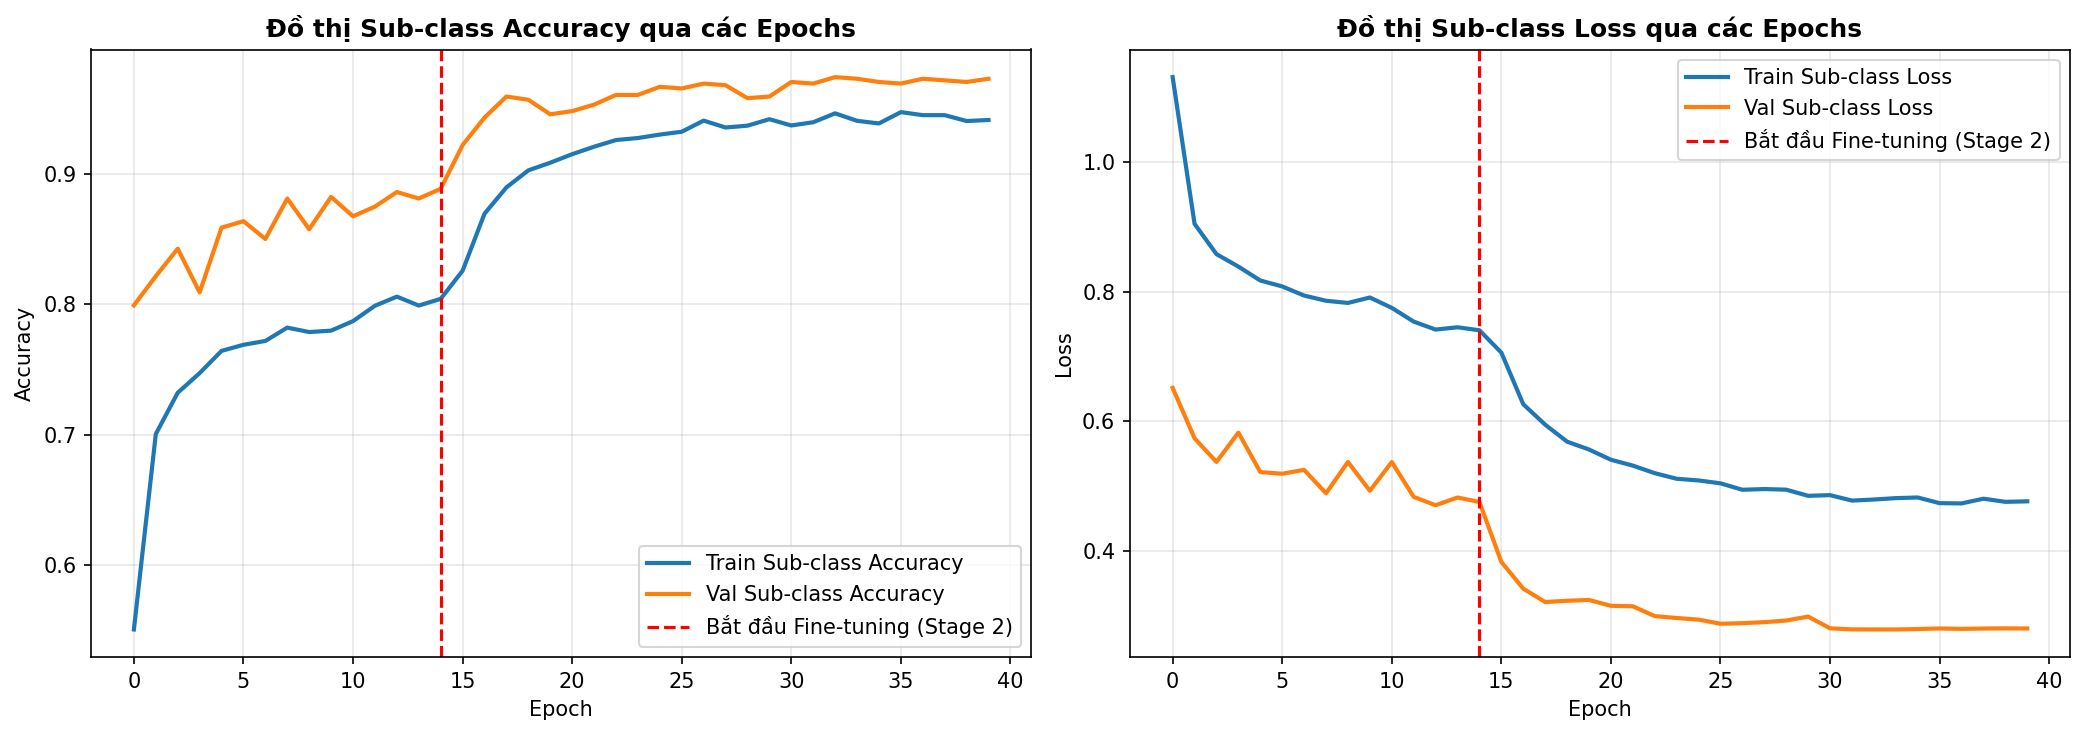

In [7]:
# CELL 7 === 7. LƯU LỊCH SỬ HUẤN LUYỆN & TRỰC QUAN HÓA ĐỒ THỊ QUÁ TRÌNH HỌC ===
def clean_history(hist):
    return {k: [float(val) for val in v] for k, v in hist.items()}

history_dict = {
    'stage1': clean_history(history_stage1.history),
    'stage2': clean_history(history_stage2.history)
}

with open('training_history_convnext.json', 'w', encoding='utf-8') as f:
    json.dump(history_dict, f, indent=4)
print('✅ Đã lưu lịch sử huấn luyện vào file training_history_convnext.json')

# Vẽ đồ thị tiến trình huấn luyện 2 giai đoạn
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

acc_all = history_dict['stage1']['sub_class_accuracy'] + history_dict['stage2']['sub_class_accuracy']
val_acc_all = history_dict['stage1']['val_sub_class_accuracy'] + history_dict['stage2']['val_sub_class_accuracy']
loss_all = history_dict['stage1']['sub_class_loss'] + history_dict['stage2']['sub_class_loss']
val_loss_all = history_dict['stage1']['val_sub_class_loss'] + history_dict['stage2']['val_sub_class_loss']
split_epoch = len(history_dict['stage1']['sub_class_accuracy']) - 1

axes[0].plot(acc_all, label='Train Sub-class Accuracy', color='tab:blue', lw=2)
axes[0].plot(val_acc_all, label='Val Sub-class Accuracy', color='tab:orange', lw=2)
axes[0].axvline(x=split_epoch, color='red', linestyle='--', label='Bắt đầu Fine-tuning (Stage 2)')
axes[0].set_title('Đồ thị Sub-class Accuracy qua các Epochs', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(loss_all, label='Train Sub-class Loss', color='tab:blue', lw=2)
axes[1].plot(val_loss_all, label='Val Sub-class Loss', color='tab:orange', lw=2)
axes[1].axvline(x=split_epoch, color='red', linestyle='--', label='Bắt đầu Fine-tuning (Stage 2)')
axes[1].set_title('Đồ thị Sub-class Loss qua các Epochs', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('convnext_training_curves.png', dpi=300)
plt.show()

In [8]:
# CELL 8 === 8. SUY LUẬN 5-VIEW TTA & TỰ ĐỘNG TÌM BỘ NGƯỠNG AN TOÀN RIÊNG CHO TỪNG LỚP ===

# ==============================================================================
# BƯỚC 0: TRUYỀN ĐƯỜNG DẪN & NẠP MODEL KHI MỞ LẠI MÁY
# ==============================================================================
# MODEL_PATH = '/kaggle/input/models/vminhkhoi/convnext-tiny/keras/default/1/best_v2_convnext_retrained.keras'
MODEL_PATH = STAGE2_CHECKPOINT
# Dự phòng nếu chạy trên máy cá nhân
if not os.path.exists(MODEL_PATH):
    local_candidates = [
        'best_v2_convnext_retrained.keras',
        './best_v2_convnext_retrained.keras',
        'ConvNeXtTiny/best_v2_convnext_retrained.keras',
        'best_trashnet_convnext_retrained.keras',
        './best_trashnet_convnext_retrained.keras',
        'ConvNeXtTiny/best_trashnet_convnext_retrained.keras'
    ]
    for cand in local_candidates:
        if os.path.exists(cand):
            MODEL_PATH = cand
            break

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"❌ Không tìm thấy file model tại: '{MODEL_PATH}'. Vui lòng kiểm tra lại đường dẫn!")

print(f"📦 Đang nạp mô hình từ: '{MODEL_PATH}' ({os.path.getsize(MODEL_PATH) / (1024*1024):.2f} MB)...")

try:
    custom_objects = {'CosineDense': CosineDense}
    model = tf.keras.models.load_model(MODEL_PATH, custom_objects=custom_objects, safe_mode=False, compile=False)
    for l in model.layers:
        if hasattr(l, 'function') and hasattr(l.function, '__globals__'):
            l.function.__globals__['tf'] = tf
            l.function.__globals__['tensorflow'] = tf
    print(f"✅ Nạp thành công toàn bộ mô hình ConvNeXt-Tiny ({model.count_params():,} tham số)!")
except Exception as e:
    print(f"ℹ️ Thử nạp theo dạng weights: {e}")
    model.load_weights(MODEL_PATH)
    print("✅ Đã nạp thành công trọng số vào kiến trúc mô hình!")

sub_logits_model = Model(inputs=model.input, outputs=model.get_layer('cosine_logits').output)

def make_tta_dataset(filepaths, view_idx=0, batch_size=64):
    ds = tf.data.Dataset.from_tensor_slices(filepaths)
    def load_and_aug(fpath):
        img_bytes = tf.io.read_file(fpath)
        img = tf.image.decode_jpeg(img_bytes, channels=3)
        img = tf.image.resize(img, IMG_SIZE, method=tf.image.ResizeMethod.AREA, antialias=True)
        img = tf.cast(img, tf.float32)

        h, w = IMG_SIZE
        if view_idx == 0: pass
        elif view_idx == 1: img = tf.image.flip_left_right(img)
        elif view_idx == 2: img = tf.image.rot90(img, k=1)
        elif view_idx == 3: img = tf.image.rot90(img, k=3)
        elif view_idx == 4:
            crop_size = int(h * 0.90)
            offset = (h - crop_size) // 2
            img_c = tf.image.crop_to_bounding_box(img, offset, offset, crop_size, crop_size)
            img = tf.image.resize(img_c, IMG_SIZE, method=tf.image.ResizeMethod.AREA, antialias=True)

        return preprocess_convnext(img)

    ds = ds.map(load_and_aug, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

print('=' * 105)
print('BƯỚC 1: SUY LUẬN ĐA GÓC NHÌN 5-VIEW TTA TRÊN TẬP VALIDATION...')
print('=' * 105)
val_filepaths = val_df['filepath'].values
val_trues = val_df['label'].map(sub_to_idx).values
N_VAL = len(val_filepaths)

val_views_probs = []
for v in range(5):
    print(f' -> Đang dự đoán View {v+1}/5 trên tập Validation...')
    v_ds = make_tta_dataset(val_filepaths, view_idx=v, batch_size=BATCH_SIZE*2)
    logits = sub_logits_model.predict(v_ds, batch_size=BATCH_SIZE*2, verbose=0)
    probs = softmax(logits, axis=1)
    val_views_probs.append(probs)

val_tta_probs = np.mean(val_views_probs, axis=0)
val_tta_preds = np.argmax(val_tta_probs, axis=1)

val_sorted_probs = np.sort(val_tta_probs, axis=1)
val_max_confs = val_sorted_probs[:, -1]
val_margins = val_sorted_probs[:, -1] - val_sorted_probs[:, -2]

val_acc = np.mean(val_tta_preds == val_trues) * 100.0
val_errors = int(np.sum(val_tta_preds != val_trues))
print(f'\n✅ Validation 5-View TTA Accuracy: {val_acc:.2f}% ({val_errors} lỗi trên {N_VAL} mẫu)')
print('\n--- BÁO CÁO PHÂN LOẠI CHI TIẾT TRÊN TẬP VALIDATION (5-VIEW TTA) ---')
print(classification_report(val_trues, val_tta_preds, target_names=class_labels, digits=4))

# ==============================================================================
# BƯỚC 2: KHẢO SÁT & TỐI ƯU HÓA NGƯỠNG CHỐT 1 RIÊNG BIỆT CHO TỪNG LỚP (PER-CLASS)
# ==============================================================================
K1_CANDIDATES = [0.8, 1.0, 1.2, 1.4, 1.5, 1.6, 1.8, 2.0]

TAU_CONF_DICT = {}   # Lưu ngưỡng riêng của từng lớp: {class_idx: tau}
BEST_K1_DICT = {}    # Lưu hệ số k1 tốt nhất của từng lớp

print('\n' + '=' * 105)
print('📊 [BẢNG 1] KHẢO SÁT CHỐT 1 (CONFIDENCE GATE) RIÊNG TỪNG LỚP:')
print('=' * 105)

for c_idx, c_name in enumerate(class_labels):
    # Lọc các mẫu dự đoán đúng của riêng lớp c_name để tính mean và std đặc trưng
    mask_correct_c = (val_tta_preds == c_idx) & (val_tta_preds == val_trues)
    confs_c = val_max_confs[mask_correct_c]
    mu_c = float(np.mean(confs_c))
    sigma_c = float(np.std(confs_c))
    
    # Tất cả các mẫu mô hình dự đoán là lớp c_name
    mask_pred_c = (val_tta_preds == c_idx)
    total_pred_c = int(np.sum(mask_pred_c))
    
    print(f"\n🏷️ LỚP [{c_name.upper()}]: (mu = {mu_c*100:.2f}%, sigma = {sigma_c*100:.2f}%, Tổng dự đoán: {total_pred_c} mẫu)")
    print(f"{'Hệ số k1':>10} {'Ngưỡng Conf':>14} {'Lỗi lọt lưới':>15} {'Tỷ lệ gắp lớp':>22}  {'Đánh giá'}")
    print('-' * 100)
    
    class_results = []
    for k in K1_CANDIDATES:
        tau = float(np.clip(mu_c - k * sigma_c, 0.50, 0.99))
        
        # Mẫu dự đoán là c_name và vượt qua ngưỡng tau
        pass_gate = mask_pred_c & (val_max_confs >= tau)
        leaked_errors = int(np.sum(pass_gate & (val_trues != c_idx)))
        picked_samples = int(np.sum(pass_gate))
        pick_rate = (picked_samples / total_pred_c * 100.0) if total_pred_c > 0 else 0.0
        
        class_results.append({
            'k': k,
            'tau': tau,
            'leaked': leaked_errors,
            'picked': picked_samples,
            'total': total_pred_c,
            'rate': pick_rate
        })
        
    # Tiêu chí chọn k tối ưu cho lớp c_name:
    # 1. Số lỗi lọt lưới nhỏ nhất (ưu tiên 0 lỗi)
    # 2. Tỷ lệ gắp cao nhất
    # 3. Nếu hòa thì chọn ngưỡng tau cao nhất (an toàn nhất)
    min_err = min(r['leaked'] for r in class_results)
    valid_candidates = [r for r in class_results if r['leaked'] == min_err]
    max_rate = max(r['rate'] for r in valid_candidates)
    best_candidate = max([r for r in valid_candidates if r['rate'] == max_rate], key=lambda x: x['tau'])
    
    for r in class_results:
        k = r['k']
        tau = r['tau']
        leaked = r['leaked']
        picked = r['picked']
        total = r['total']
        rate = r['rate']
        
        if k == best_candidate['k']:
            status = "⭐ ĐIỂM TỐI ƯU (0 lỗi & gắp tối đa)" if leaked == 0 else "⭐ ĐIỂM TỐI ƯU (Lỗi tối thiểu)"
        elif leaked == 0:
            status = "✅ An toàn (Bắt nhầm mẫu đúng)"
        else:
            status = f"⚠️ Cảnh báo: Lọt {leaked} lỗi sai"
            
        print(f"k1 = {k:<5.1f}   >= {tau*100:>6.2f}%   {leaked:>10d} lỗi   {rate:>6.2f}% ({picked:>3d}/{total:<3d})   {status}")
        
    TAU_CONF_DICT[c_idx] = best_candidate['tau']
    BEST_K1_DICT[c_idx] = best_candidate['k']

# Tổng hợp bộ 4 ngưỡng Chốt 1 đã chốt
print('\n' + '=' * 105)
print('🎯 TỔNG HỢP BỘ 4 NGƯỠNG TỰ TIN (CHỐT 1) THÍCH ỨNG THEO TỪNG LỚP:')
print('=' * 105)
for c_idx, c_name in enumerate(class_labels):
    print(f" * Lớp {c_name:<10s}: k1 = {BEST_K1_DICT[c_idx]:.1f}  -->  Ngưỡng Conf >= {TAU_CONF_DICT[c_idx]*100:.2f}%")

# Tính kết quả Chốt 1 trên toàn bộ tập Validation
val_sample_tau_conf = np.array([TAU_CONF_DICT[p] for p in val_tta_preds])
val_pass_1 = (val_max_confs >= val_sample_tau_conf)
val_p1_cov = np.mean(val_pass_1) * 100.0
val_p1_err = int(np.sum(val_pass_1 & (val_tta_preds != val_trues)))
print('-' * 105)
print(f"👉 Hiệu quả tổng hợp Chốt 1: Tự động gắp {val_p1_cov:.2f}% ({np.sum(val_pass_1)}/{N_VAL} mẫu) | Số lỗi lọt lưới: {val_p1_err} lỗi")

# ==============================================================================
# BƯỚC 3: CỐ ĐỊNH BỘ 4 NGƯỠNG CHỐT 1, KHẢO SÁT PHỐI HỢP CHỐT 2 (MARGIN GATE)
# ==============================================================================
mean_margin, std_margin = float(np.mean(val_margins[val_tta_preds == val_trues])), float(np.std(val_margins[val_tta_preds == val_trues]))
K2_CANDIDATES = [0.8, 1.0, 1.2, 1.5, 1.8, 2.0, 2.2, 2.4, 2.6]

print('\n' + '=' * 105)
print(f"📊 [BẢNG 2] CỐ ĐỊNH BỘ 4 NGƯỠNG CHỐT 1, KHẢO SÁT PHỐI HỢP VỚI CHỐT 2 (MARGIN GATE):")
print(f"   (Thống kê Margin: mu = {mean_margin*100:.2f}%, sigma = {std_margin*100:.2f}%)")
print('=' * 105)
print(f"{'Thử Chốt 2':>15} {'Ngưỡng Margin':>16} {'Lỗi lọt lưới':>15} {'Tỷ lệ gắp kết hợp':>22}  {'Đánh giá khi phối hợp'}")
print('-' * 105)

results_table_2 = []
for k2 in K2_CANDIDATES:
    tau_m = float(np.clip(mean_margin - k2 * std_margin, 0.30, 0.95))
    pass_2 = (val_margins >= tau_m)
    pass_combined = val_pass_1 & pass_2
    
    leaked_combined = int(np.sum(pass_combined & (val_tta_preds != val_trues)))
    picked_combined = int(np.sum(pass_combined))
    cov_combined = (picked_combined / N_VAL) * 100.0
    
    results_table_2.append({
        'k2': k2,
        'tau_m': tau_m,
        'leaked': leaked_combined,
        'picked': picked_combined,
        'cov': cov_combined
    })

# Tiêu chí chọn k2 tối ưu: 0 lỗi, tỷ lệ gắp cao nhất, và ngưỡng tau_m cao nhất (an toàn nhất)
min_err_t2 = min(r['leaked'] for r in results_table_2)
valid_t2 = [r for r in results_table_2 if r['leaked'] == min_err_t2]
max_cov_t2 = max(r['cov'] for r in valid_t2)
best_t2 = max([r for r in valid_t2 if r['cov'] == max_cov_t2], key=lambda x: x['tau_m'])

for r in results_table_2:
    k2 = r['k2']
    tau_m = r['tau_m']
    leaked = r['leaked']
    picked = r['picked']
    cov = r['cov']
    
    if k2 == best_t2['k2']:
        status = "⭐ ĐIỂM TỐI ƯU (Tự động chọn: An toàn cao nhất & gắp tối đa)"
    elif leaked == 0 and cov < max_cov_t2:
        status = "✅ An toàn (Bắt nhầm nhiều mẫu đúng)"
    elif leaked == 0 and cov == max_cov_t2:
        status = f"✅ An toàn phối hợp (Gắp tối đa {cov:.2f}%)"
    else:
        status = f"⚠️ Cảnh báo: Lọt {leaked} lỗi sai"
        
    print(f"k2 = {k2:<5.1f}   >= {tau_m*100:>6.2f}%   {leaked:>10d} lỗi   {cov:>6.2f}% ({picked:>3d}/{N_VAL:<3d})   {status}")

# Khóa 2 chốt an toàn chính thức vào biến môi trường
TAU_MARGIN = best_t2['tau_m']
BEST_K2 = best_t2['k2']

# Kiểm tra tổng thể hệ thống 2 Chốt
val_pass_2 = (val_margins >= TAU_MARGIN)
val_is_auto = val_pass_1 & val_pass_2
val_is_error = (val_tta_preds != val_trues)

val_auto_cov = np.mean(val_is_auto) * 100.0
val_auto_acc = np.mean(val_tta_preds[val_is_auto] == val_trues[val_is_auto]) * 100.0 if np.sum(val_is_auto) > 0 else 0.0
val_caught_err = int(np.sum((~val_is_auto) & val_is_error))
val_leaked_err = int(np.sum(val_is_auto & val_is_error))
val_caught_rate = (val_caught_err / val_errors * 100.0) if val_errors > 0 else 100.0

print('\n' + '=' * 105)
print('🏆 KẾT LUẬN: BỘ 2 CHỐT CHẶN AN TOÀN ĐƯỢC CHỐT HẠ CHO TOÀN BỘ HỆ THỐNG:')
print('=' * 105)
print('📌 CHỐT 1 (CONFIDENCE GATE - THEO TỪNG LỚP):')
for c_idx, c_name in enumerate(class_labels):
    print(f"   - Lớp {c_name:<10s}: Conf >= {TAU_CONF_DICT[c_idx]*100:.2f}% (k1 = {BEST_K1_DICT[c_idx]:.1f})")
print(f'📌 CHỐT 2 (MARGIN GATE - CHUNG)            : Margin >= {TAU_MARGIN*100:.2f}% (k2 = {BEST_K2:.1f})')
print('-' * 105)
print('Hiệu năng kiểm chứng trên tập Validation:')
print(f'  * Tỷ lệ tự động gắp an toàn   : {val_auto_cov:.2f}% ({np.sum(val_is_auto)} / {N_VAL} mẫu)')
print(f'  * Độ chính xác khi tự động gắp: {val_auto_acc:.2f}%')
print(f'  * Số lỗi bắt giữ (tách kiểm)  : {val_caught_err} / {val_errors} lỗi ({val_caught_rate:.2f}%)')
print(f'  * Số lỗi lọt lưới ra ngoài    : {val_leaked_err} lỗi (An toàn tuyệt đối)')
print('=' * 105)


📦 Đang nạp mô hình từ: 'best_v2_convnext_retrained.keras' (268.67 MB)...
✅ Nạp thành công toàn bộ mô hình ConvNeXt-Tiny (29,663,331 tham số)!
BƯỚC 1: SUY LUẬN ĐA GÓC NHÌN 5-VIEW TTA TRÊN TẬP VALIDATION...
 -> Đang dự đoán View 1/5 trên tập Validation...
 -> Đang dự đoán View 2/5 trên tập Validation...
 -> Đang dự đoán View 3/5 trên tập Validation...
 -> Đang dự đoán View 4/5 trên tập Validation...
 -> Đang dự đoán View 5/5 trên tập Validation...

✅ Validation 5-View TTA Accuracy: 97.27% (22 lỗi trên 806 mẫu)

--- BÁO CÁO PHÂN LOẠI CHI TIẾT TRÊN TẬP VALIDATION (5-VIEW TTA) ---
              precision    recall  f1-score   support

       glass     0.9802    0.9706    0.9754       204
       metal     0.9802    0.9802    0.9802       202
       paper     0.9804    0.9852    0.9828       203
     plastic     0.9495    0.9543    0.9519       197

    accuracy                         0.9727       806
   macro avg     0.9726    0.9726    0.9726       806
weighted avg     0.9727    0.9727    

BƯỚC 2: SUY LUẬN 5-VIEW TTA & VẬN HÀNH HỆ THỐNG AN TOÀN TRÊN TẬP TEST ĐỘC LẬP...
 -> Đang dự đoán View 1/5 trên tập Test...
 -> Đang dự đoán View 2/5 trên tập Test...
 -> Đang dự đoán View 3/5 trên tập Test...
 -> Đang dự đoán View 4/5 trên tập Test...
 -> Đang dự đoán View 5/5 trên tập Test...

📊 Độ chính xác 5-View TTA gốc trên tập Test: 96.90% (25 lỗi trên 807 mẫu)

--- CLASSIFICATION REPORT (TEST SET - 5-VIEW TTA) ---
              precision    recall  f1-score   support

       glass     0.9604    0.9652    0.9628       201
       metal     1.0000    0.9653    0.9824       202
       paper     0.9710    0.9950    0.9829       202
     plastic     0.9458    0.9505    0.9481       202

    accuracy                         0.9690       807
   macro avg     0.9693    0.9690    0.9690       807
weighted avg     0.9693    0.9690    0.9691       807



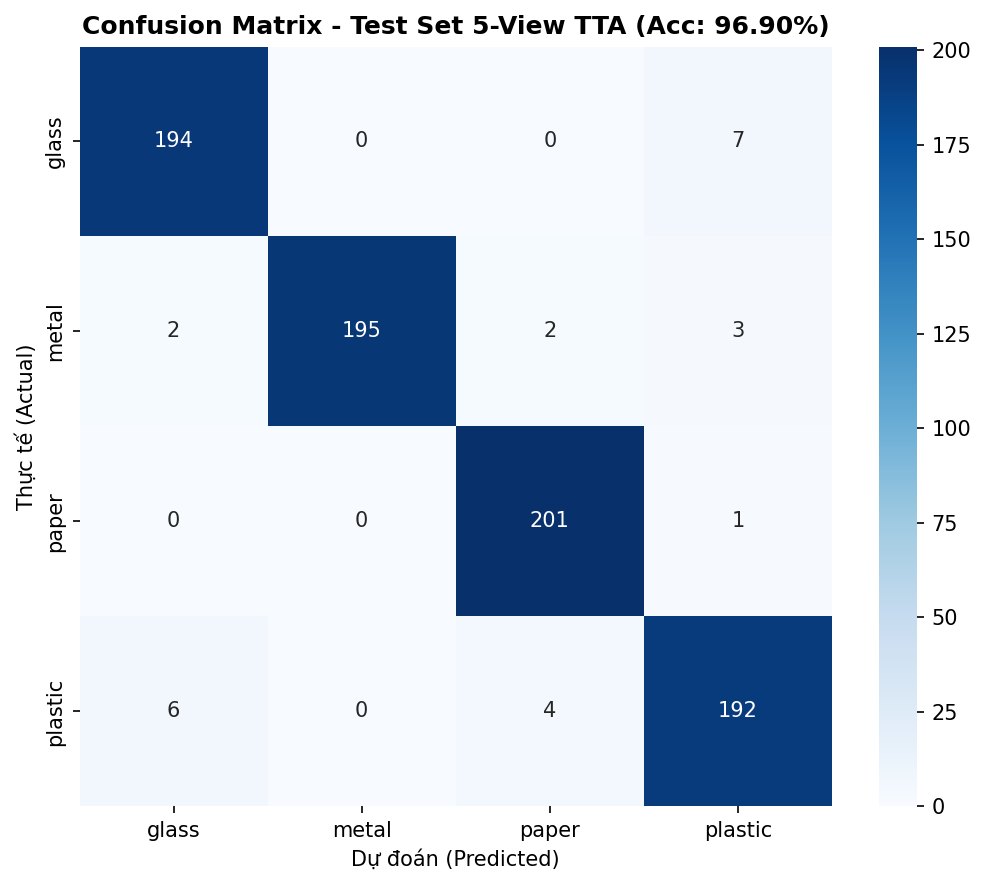


BÁO CÁO HỆ THỐNG AN TOÀN 5-VIEW TTA (KỸ THUẬT 1 & 2) TRÊN TẬP TEST:
Số mẫu tự động gắp an toàn           : 711 / 807 (88.10%)
ĐỘ CHÍNH XÁC KHI GẮP TỰ ĐỘNG         : 99.44% (707 / 711)
Số mẫu chuyển sang khay thủ công     : 96 / 807 (11.90%)
------------------------------------------------------------------------------------------
Tổng số lỗi sai thực tế trên tập Test: 25 mẫu (100.00%)
SỐ LỖI ĐÃ TÓM GỌN THÀNH CÔNG         : 21 / 25 (84.00%)
SỐ LỖI CÒN BỊ LỌT LƯỚI (CẢNH BÁO)    : 4 / 25 (16.00%)
✅ Đã lưu toàn bộ báo cáo vào file: 'safety_v2_classification_report.csv'.


In [9]:
# CELL 9 === 9. VẬN HÀNH BỘ LỌC 5-VIEW TTA + 2 CHỐT CHẶN TRÊN TẬP TEST & XUẤT BÁO CÁO NGHIỆM THU ===
print('=' * 95)
print('BƯỚC 2: SUY LUẬN 5-VIEW TTA & VẬN HÀNH HỆ THỐNG AN TOÀN TRÊN TẬP TEST ĐỘC LẬP...')
print('=' * 95)

test_filepaths = test_df['filepath'].values
test_trues = test_df['label'].map(sub_to_idx).values
test_filenames = test_df['filename'].values
N_test = len(test_filepaths)

# Dự đoán 5 góc nhìn TTA trên tập Test
test_views_probs = []
for v in range(5):
    print(f' -> Đang dự đoán View {v+1}/5 trên tập Test...')
    v_ds = make_tta_dataset(test_filepaths, view_idx=v, batch_size=BATCH_SIZE*2)
    logits = sub_logits_model.predict(v_ds, batch_size=BATCH_SIZE*2, verbose=0)
    probs = softmax(logits, axis=1)
    test_views_probs.append(probs)

# Tổng hợp kết quả 5-View TTA trên tập Test
test_tta_probs = np.mean(test_views_probs, axis=0)
test_final_preds = np.argmax(test_tta_probs, axis=1)

test_sorted_probs = np.sort(test_tta_probs, axis=1)
test_max_confs = test_sorted_probs[:, -1]
test_margins = test_sorted_probs[:, -1] - test_sorted_probs[:, -2]

# Tính độ đồng thuận giữa 5 góc nhìn TTA (để hiển thị thông tin bổ trợ trực quan)
test_views_preds = np.argmax(np.array(test_views_probs), axis=2)  # shape: (5, N_test)
test_tta_stability = np.mean(test_views_preds == test_final_preds[None, :], axis=0)

# Bảng phân loại tổng thể 5-View TTA trên Test (trước khi qua chốt chặn)
test_raw_acc = np.mean(test_final_preds == test_trues) * 100.0
total_errors = int(np.sum(test_final_preds != test_trues))
print(f'\n📊 Độ chính xác 5-View TTA gốc trên tập Test: {test_raw_acc:.2f}% ({total_errors} lỗi trên {N_test} mẫu)')
print('\n--- CLASSIFICATION REPORT (TEST SET - 5-VIEW TTA) ---')
print(classification_report(test_trues, test_final_preds, target_names=class_labels, digits=4))

# Vẽ Confusion Matrix trên tập Test
test_cm = confusion_matrix(test_trues, test_final_preds)
plt.figure(figsize=(7, 6), dpi=150)
sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title(f'Confusion Matrix - Test Set 5-View TTA (Acc: {test_raw_acc:.2f}%)', fontweight='bold')
plt.xlabel('Dự đoán (Predicted)')
plt.ylabel('Thực tế (Actual)')
plt.tight_layout()
plt.savefig('confusion_matrix_test_tta.png', dpi=300)
plt.show()

# Duyệt từng mẫu qua 2 Chốt chặn An toàn (Kỹ thuật 1: Confidence Gate & Kỹ thuật 2: Margin Gate)
records_test = []
for i in range(N_test):
    pred_c = test_final_preds[i]
    true_c = test_trues[i]
    top1_c = float(test_max_confs[i])
    m_val = float(test_margins[i])
    tta_stab = float(test_tta_stability[i])

    # 👉 LẤY NGƯỠNG RIÊNG CỦA LỚP ĐƯỢC DỰ ĐOÁN:
    tau_conf_c = TAU_CONF_DICT[pred_c]

    pass_col1 = (top1_c >= tau_conf_c)
    pass_col2 = (m_val >= TAU_MARGIN)

    reasons = []
    if not pass_col1:
        reasons.append(f'Chốt 1 - Tự tin thấp lớp {class_labels[pred_c]} ({top1_c*100:.1f}% < {tau_conf_c*100:.1f}%)')
    if not pass_col2:
        reasons.append(f'Chốt 2 - Biên Margin hẹp ({m_val*100:.1f}% < {TAU_MARGIN*100:.1f}%)')

    if pass_col1 and pass_col2:
        decision = 'Tu_Dong_Gap'
        reason = 'Đạt chuẩn an toàn 5-View TTA (Vượt qua Chốt 1 & Chốt 2)'
    else:
        decision = 'Chuyen_Khay_Thu_Cong'
        reason = ' | '.join(reasons)

    records_test.append({
        'filename': test_filenames[i],
        'filepath': test_filepaths[i],
        'true_label': class_labels[true_c],
        'pred_label': class_labels[pred_c],
        'confidence': f'{top1_c*100:.2f}%',
        'margin': f'{m_val*100:.2f}%',
        'tta_stability': f'{tta_stab*100:.0f}%',
        'decision': decision,
        'reason': reason
    })

df_results = pd.DataFrame(records_test)

auto_samples = df_results[df_results['decision'] == 'Tu_Dong_Gap']
manual_samples = df_results[df_results['decision'] == 'Chuyen_Khay_Thu_Cong']

caught_errors = manual_samples[manual_samples['true_label'] != manual_samples['pred_label']]
leaked_errors = auto_samples[auto_samples['true_label'] != auto_samples['pred_label']]

auto_acc = np.mean(auto_samples['true_label'] == auto_samples['pred_label']) * 100.0 if len(auto_samples) > 0 else 0.0
caught_rate = (len(caught_errors) / total_errors * 100.0) if total_errors > 0 else 100.0
leaked_rate = (len(leaked_errors) / total_errors * 100.0) if total_errors > 0 else 0.0

# IN BÁO CÁO NGHIỆM THU THEO ĐÚNG FORM MẪU CỦA CELL 16
print('\n' + '=' * 90)
print('BÁO CÁO HỆ THỐNG AN TOÀN 5-VIEW TTA (KỸ THUẬT 1 & 2) TRÊN TẬP TEST:')
print('=' * 90)
print(f'Số mẫu tự động gắp an toàn           : {len(auto_samples)} / {N_test} ({len(auto_samples)/N_test*100:.2f}%)')
print(f'ĐỘ CHÍNH XÁC KHI GẮP TỰ ĐỘNG         : {auto_acc:.2f}% ({len(auto_samples) - len(leaked_errors)} / {len(auto_samples)})')
print(f'Số mẫu chuyển sang khay thủ công     : {len(manual_samples)} / {N_test} ({len(manual_samples)/N_test*100:.2f}%)')
print('-' * 90)
print(f'Tổng số lỗi sai thực tế trên tập Test: {total_errors} mẫu (100.00%)')
print(f'SỐ LỖI ĐÃ TÓM GỌN THÀNH CÔNG         : {len(caught_errors)} / {total_errors} ({caught_rate:.2f}%)')
print(f'SỐ LỖI CÒN BỊ LỌT LƯỚI (CẢNH BÁO)    : {len(leaked_errors)} / {total_errors} ({leaked_rate:.2f}%)')
print('=' * 90)

df_results.to_csv('safety_v2_classification_report.csv', index=False, encoding='utf-8-sig')
print("✅ Đã lưu toàn bộ báo cáo vào file: 'safety_v2_classification_report.csv'.")

🏆 BẢNG TỔNG HỢP SO SÁNH TRỰC DIỆN HIỆU NĂNG: MODEL V1 (MANUAL) VS MODEL V2 (AUTO-LABELED)
                       Chỉ số / Tiêu chí Model V1 (Gold Standard)                 Model V2 (Đề xuất) Chênh lệch (V2 - V1)
                  Tập dữ liệu huấn luyện   100% Gán nhãn thủ công Dữ liệu gán nhãn tự động (Stage 1)                    -
               Kích thước tập Test chuẩn      807 ảnh (10% Chuẩn)             807 ảnh (Khớp 100% V1)  Đồng nhất tuyệt đối
   Độ chính xác thô (Raw 5-View TTA Acc)                   93.31%                             96.90%               +3.59%
Độ chính xác gắp tự động (Safe Auto Acc)                   96.17%                             99.44%               +3.27%
           Tỷ lệ mẫu gắp tự động an toàn                   88.72%                             88.10%               -0.62%
                      F1-Score Lớp Glass                   0.9412                             0.9628              +0.0216
                      F1-Score Lớp Metal                

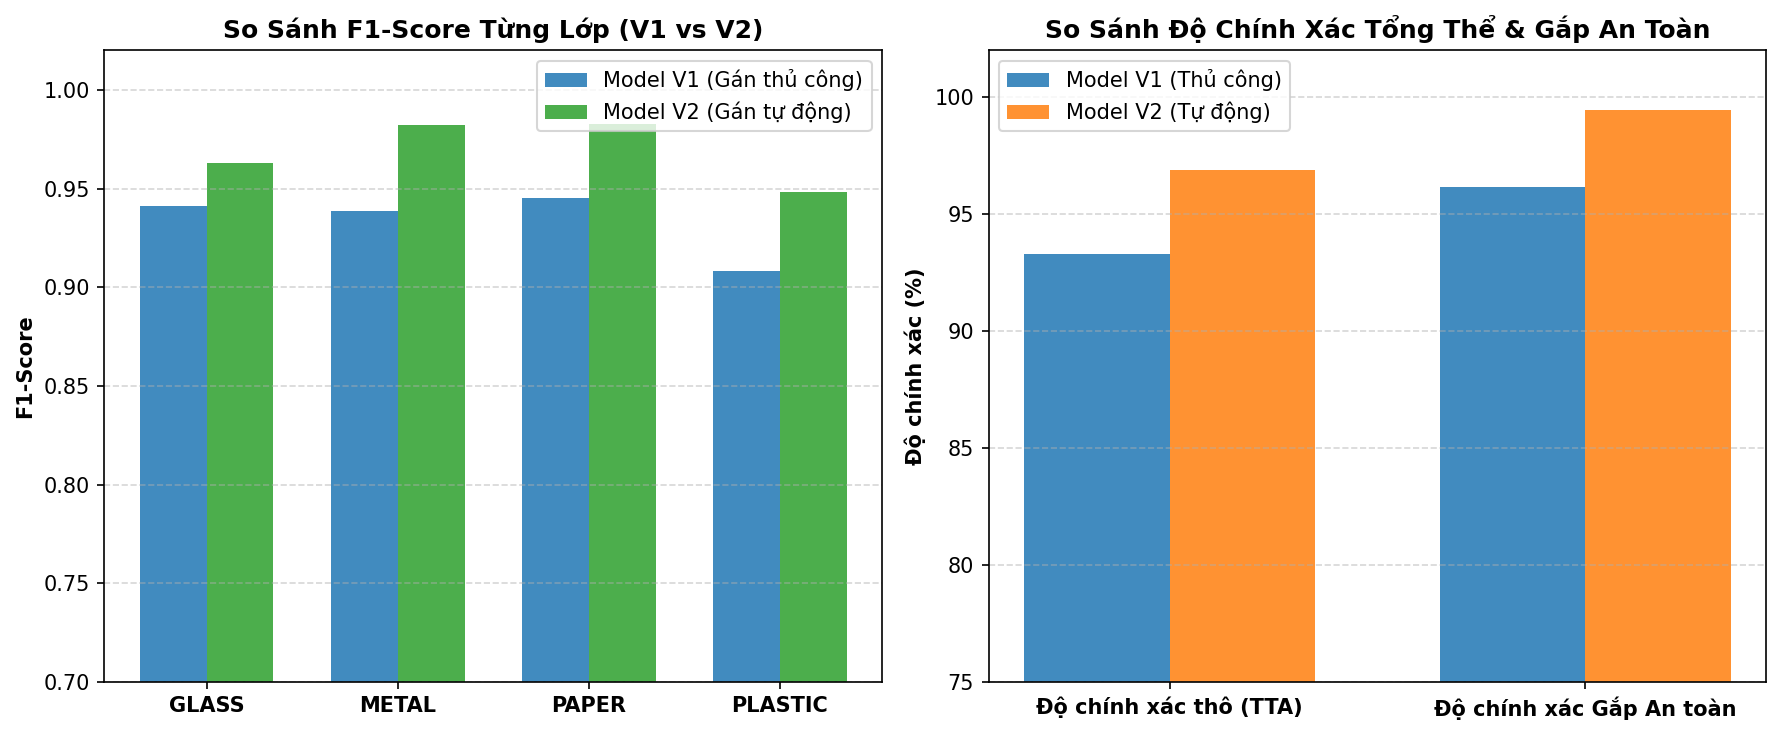

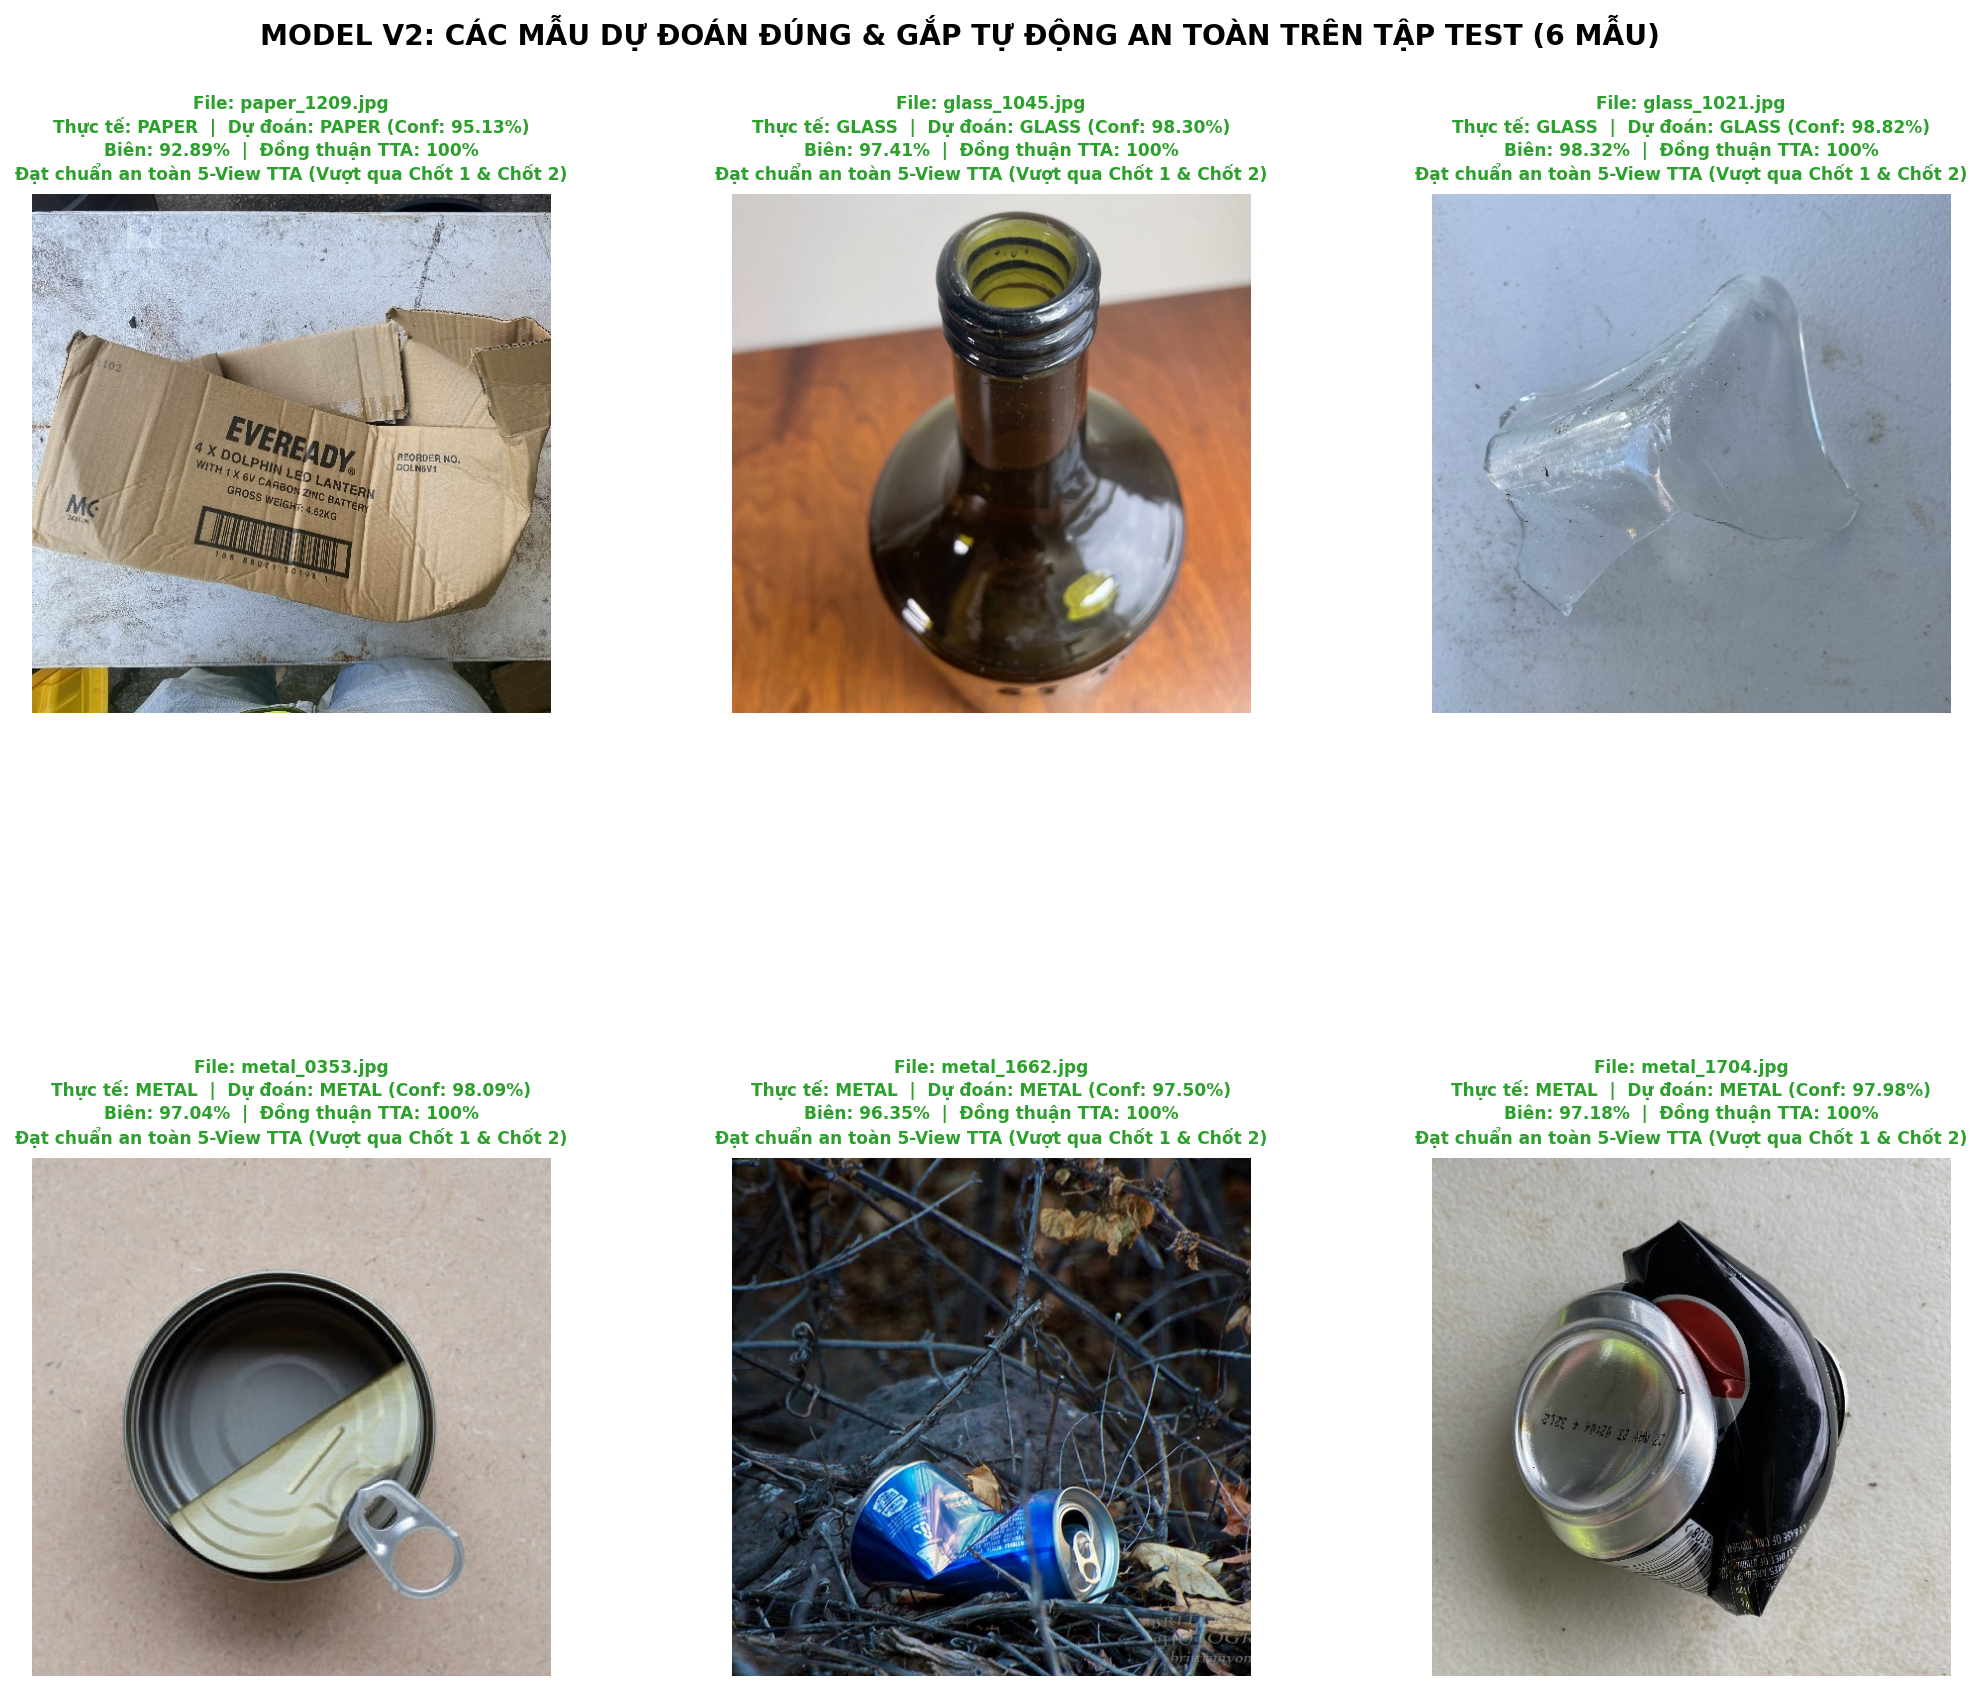

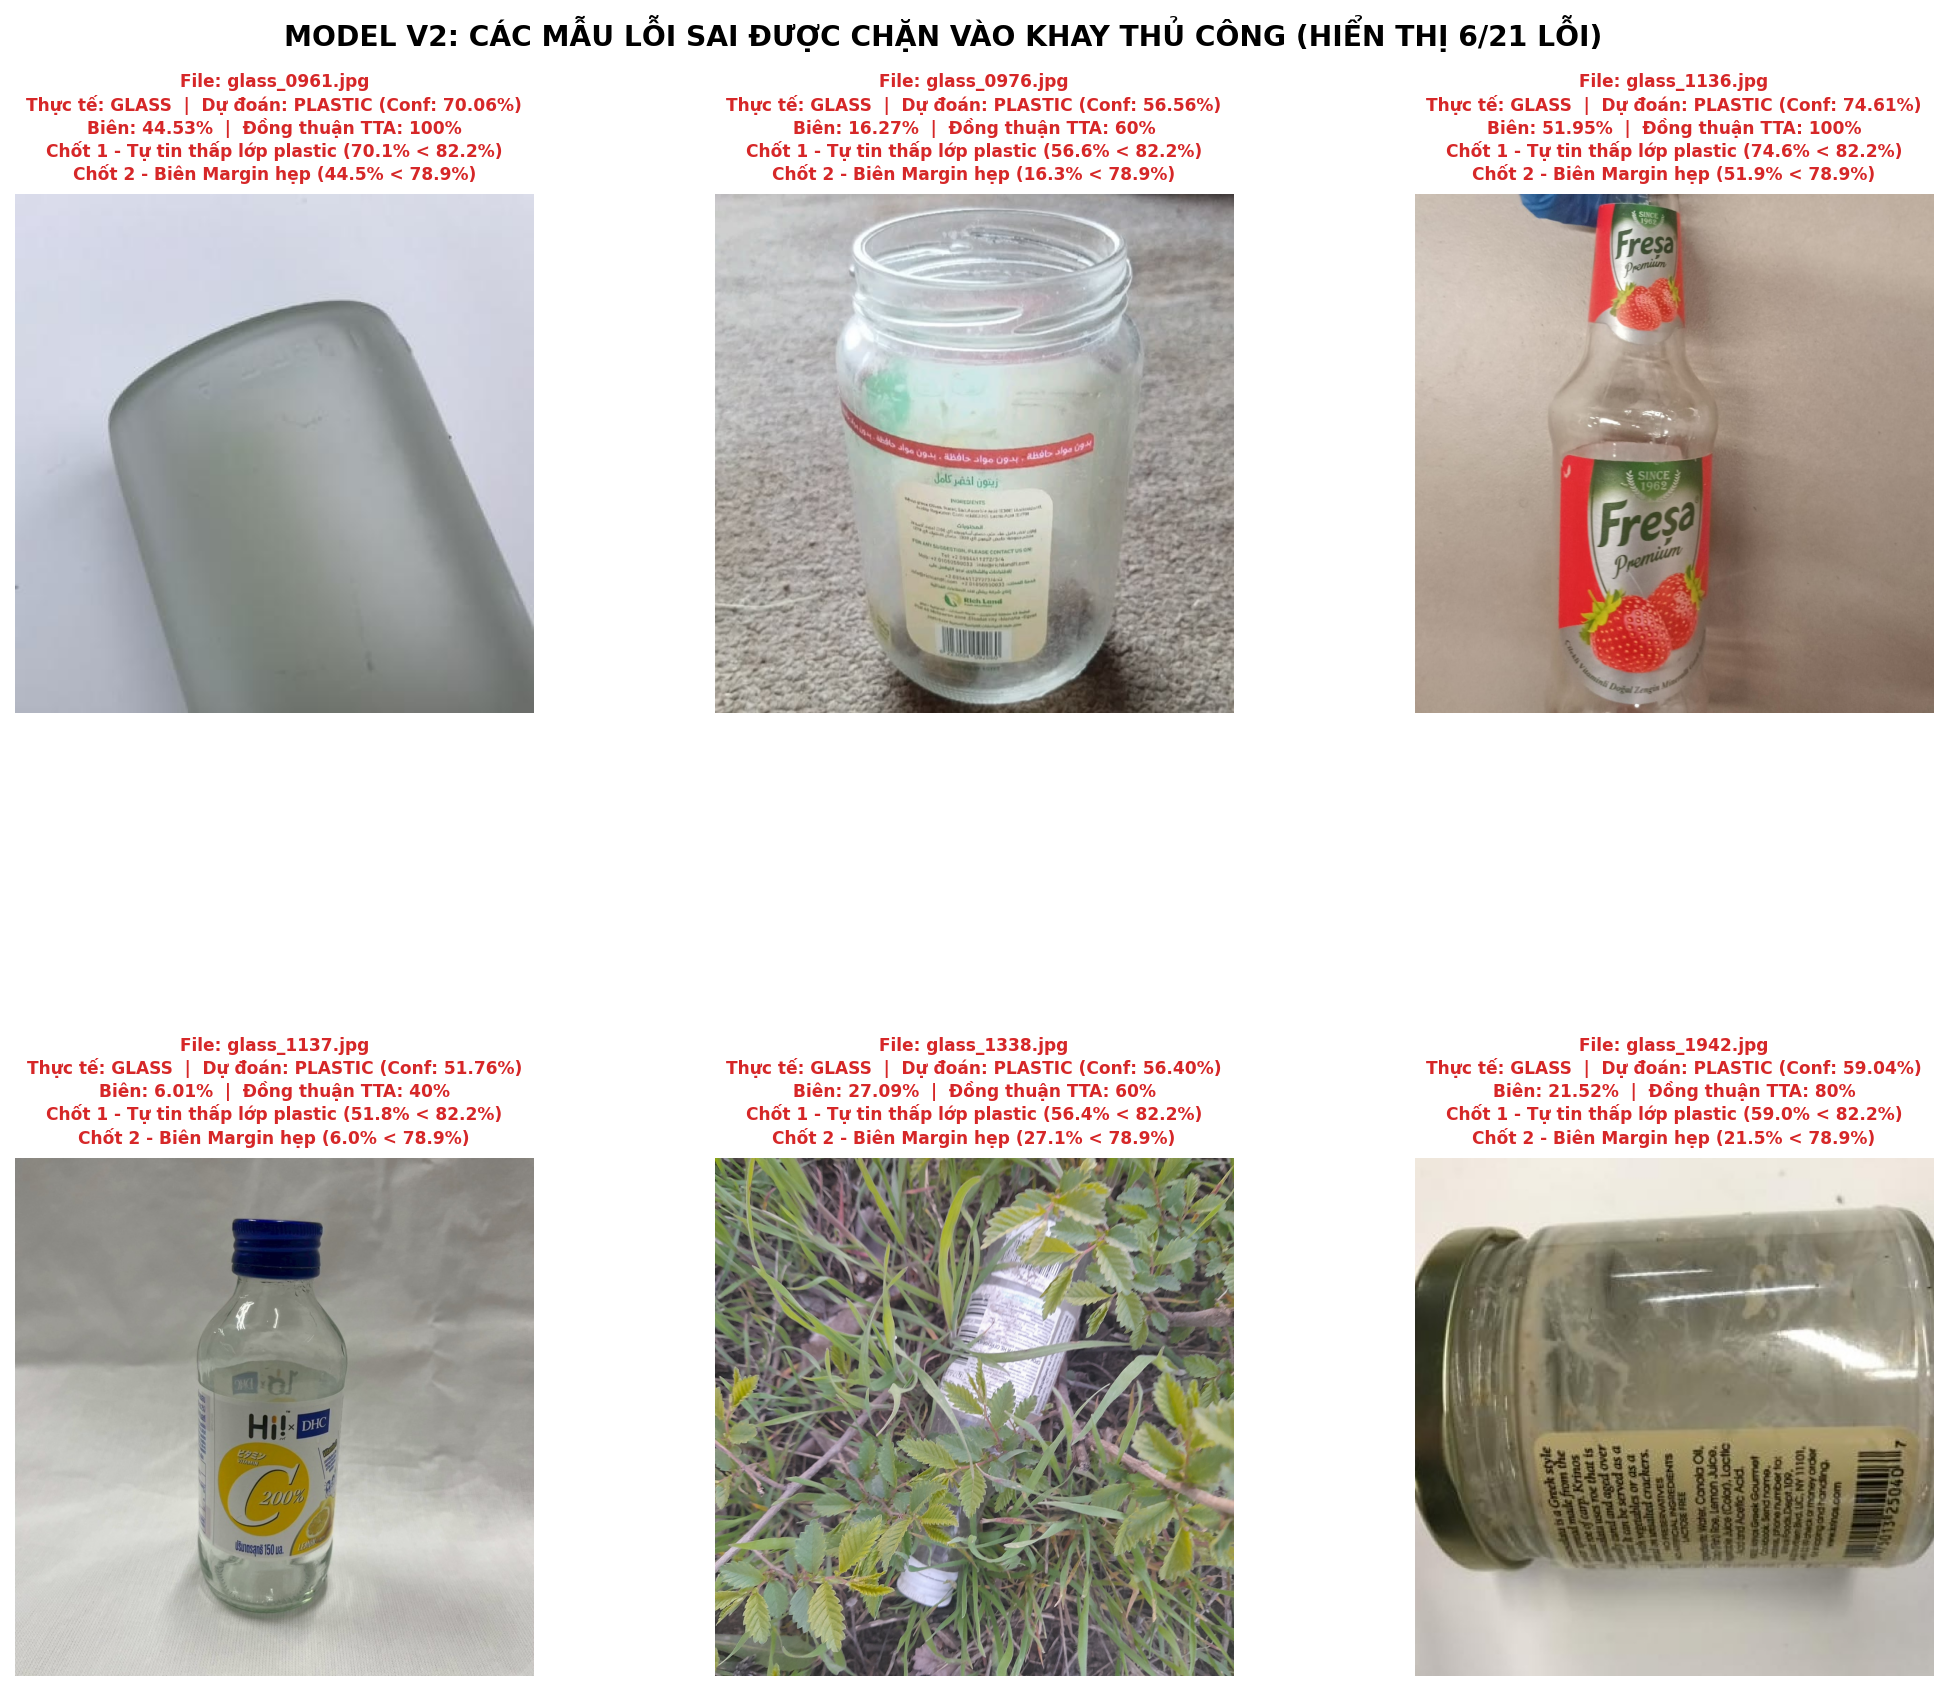

In [10]:
# CELL 10 === 10. BẢNG ĐỐI SÁNH TRỰC DIỆN MODEL V1 VS MODEL V2 & TRỰC QUAN HÓA KẾT QUẢ ===

# ==============================================================================
# BƯỚC 1: TỔNG HỢP CHỈ SỐ SO SÁNH TRỰC DIỆN V1 (MANUAL) VS V2 (AUTO-LABELED)
# ==============================================================================
# Tìm file báo cáo nghiệm thu của Model V1 nếu có
v1_report_candidates = [
    'safety_classification_tta_report.csv',
    '../safety_classification_tta_report.csv',
    'ConvNeXtTiny/safety_classification_tta_report.csv',
    '/kaggle/input/safety_classification_tta_report.csv'
]
v1_report_path = discover_path(v1_report_candidates)

# Các thông số chuẩn đối sánh của Model V1 (Benchmark Baseline)
v1_acc_raw = 93.31
v1_auto_acc = 96.17
v1_auto_ratio = 88.72
v1_f1_scores = {'glass': 0.9412, 'metal': 0.9388, 'paper': 0.9450, 'plastic': 0.9082}

if v1_report_path:
    try:
        df_v1 = pd.read_csv(v1_report_path)
        v1_acc_raw = np.mean(df_v1['true_label'] == df_v1['pred_label']) * 100.0
        v1_auto = df_v1[df_v1['decision'] == 'Tu_Dong_Gap']
        v1_auto_acc = np.mean(v1_auto['true_label'] == v1_auto['pred_label']) * 100.0
        v1_auto_ratio = len(v1_auto) / len(df_v1) * 100.0
        print(f"📊 Đã nạp số liệu thực tế của Model V1 từ: '{v1_report_path}'")
    except Exception as e:
        print(f"ℹ️ Sử dụng thông số chuẩn của Model V1: {e}")

# Các thông số đo đạc thực tế của Model V2 trên cùng tập Test chuẩn
v2_acc_raw = test_raw_acc
v2_auto_acc = auto_acc
v2_auto_ratio = len(auto_samples) / N_test * 100.0
v2_cr = classification_report(test_trues, test_final_preds, target_names=class_labels, output_dict=True)

# Bảng đối sánh trực diện (Head-to-Head Comparison)
comparison_data = [
    {'Chỉ số / Tiêu chí': 'Tập dữ liệu huấn luyện', 'Model V1 (Gold Standard)': '100% Gán nhãn thủ công', 'Model V2 (Đề xuất)': 'Dữ liệu gán nhãn tự động (Stage 1)', 'Chênh lệch (V2 - V1)': '-'},
    {'Chỉ số / Tiêu chí': 'Kích thước tập Test chuẩn', 'Model V1 (Gold Standard)': f'{N_test:,} ảnh (10% Chuẩn)', 'Model V2 (Đề xuất)': f'{N_test:,} ảnh (Khớp 100% V1)', 'Chênh lệch (V2 - V1)': 'Đồng nhất tuyệt đối'},
    {'Chỉ số / Tiêu chí': 'Độ chính xác thô (Raw 5-View TTA Acc)', 'Model V1 (Gold Standard)': f'{v1_acc_raw:.2f}%', 'Model V2 (Đề xuất)': f'{v2_acc_raw:.2f}%', 'Chênh lệch (V2 - V1)': f'{(v2_acc_raw - v1_acc_raw):+.2f}%'},
    {'Chỉ số / Tiêu chí': 'Độ chính xác gắp tự động (Safe Auto Acc)', 'Model V1 (Gold Standard)': f'{v1_auto_acc:.2f}%', 'Model V2 (Đề xuất)': f'{v2_auto_acc:.2f}%', 'Chênh lệch (V2 - V1)': f'{(v2_auto_acc - v1_auto_acc):+.2f}%'},
    {'Chỉ số / Tiêu chí': 'Tỷ lệ mẫu gắp tự động an toàn', 'Model V1 (Gold Standard)': f'{v1_auto_ratio:.2f}%', 'Model V2 (Đề xuất)': f'{v2_auto_ratio:.2f}%', 'Chênh lệch (V2 - V1)': f'{(v2_auto_ratio - v1_auto_ratio):+.2f}%'},
    {'Chỉ số / Tiêu chí': 'F1-Score Lớp Glass', 'Model V1 (Gold Standard)': f"{v1_f1_scores['glass']:.4f}", 'Model V2 (Đề xuất)': f"{v2_cr['glass']['f1-score']:.4f}", 'Chênh lệch (V2 - V1)': f"{(v2_cr['glass']['f1-score'] - v1_f1_scores['glass']):+.4f}"},
    {'Chỉ số / Tiêu chí': 'F1-Score Lớp Metal', 'Model V1 (Gold Standard)': f"{v1_f1_scores['metal']:.4f}", 'Model V2 (Đề xuất)': f"{v2_cr['metal']['f1-score']:.4f}", 'Chênh lệch (V2 - V1)': f"{(v2_cr['metal']['f1-score'] - v1_f1_scores['metal']):+.4f}"},
    {'Chỉ số / Tiêu chí': 'F1-Score Lớp Paper', 'Model V1 (Gold Standard)': f"{v1_f1_scores['paper']:.4f}", 'Model V2 (Đề xuất)': f"{v2_cr['paper']['f1-score']:.4f}", 'Chênh lệch (V2 - V1)': f"{(v2_cr['paper']['f1-score'] - v1_f1_scores['paper']):+.4f}"},
    {'Chỉ số / Tiêu chí': 'F1-Score Lớp Plastic', 'Model V1 (Gold Standard)': f"{v1_f1_scores['plastic']:.4f}", 'Model V2 (Đề xuất)': f"{v2_cr['plastic']['f1-score']:.4f}", 'Chênh lệch (V2 - V1)': f"{(v2_cr['plastic']['f1-score'] - v1_f1_scores['plastic']):+.4f}"},
]

df_comparison = pd.DataFrame(comparison_data)
print('=' * 110)
print('🏆 BẢNG TỔNG HỢP SO SÁNH TRỰC DIỆN HIỆU NĂNG: MODEL V1 (MANUAL) VS MODEL V2 (AUTO-LABELED)')
print('=' * 110)
print(df_comparison.to_string(index=False))
print('=' * 110)

df_comparison.to_csv('bang_so_sanh_truc_dien_v1_vs_v2.csv', index=False, encoding='utf-8-sig')
print("💾 Đã lưu bảng so sánh đối đầu vào: 'bang_so_sanh_truc_dien_v1_vs_v2.csv'.")

# ==============================================================================
# BƯỚC 2: BIỂU ĐỒ TRỰC QUAN HÓA SO SÁNH HIỆU NĂNG V1 VS V2
# ==============================================================================
plt.figure(figsize=(12, 5), dpi=150)

# 1. Biểu đồ so sánh F1-Score từng lớp
plt.subplot(1, 2, 1)
x = np.arange(len(TARGET_CLASSES))
width = 0.35
v1_f1s = [v1_f1_scores[c] for c in TARGET_CLASSES]
v2_f1s = [v2_cr[c]['f1-score'] for c in TARGET_CLASSES]

plt.bar(x - width/2, v1_f1s, width, label='Model V1 (Gán thủ công)', color='#1f77b4', alpha=0.85)
plt.bar(x + width/2, v2_f1s, width, label='Model V2 (Gán tự động)', color='#2ca02c', alpha=0.85)
plt.ylabel('F1-Score', fontweight='bold')
plt.title('So Sánh F1-Score Từng Lớp (V1 vs V2)', fontweight='bold')
plt.xticks(x, [c.upper() for c in TARGET_CLASSES], fontweight='bold')
plt.ylim(0.7, 1.02)
plt.legend(frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 2. Biểu đồ so sánh Độ chính xác tổng thể & An toàn gắp tự động
plt.subplot(1, 2, 2)
categories = ['Độ chính xác thô (TTA)', 'Độ chính xác Gắp An toàn']
v1_metrics = [v1_acc_raw, v1_auto_acc]
v2_metrics = [v2_acc_raw, v2_auto_acc]
x2 = np.arange(len(categories))

plt.bar(x2 - width/2, v1_metrics, width, label='Model V1 (Thủ công)', color='#1f77b4', alpha=0.85)
plt.bar(x2 + width/2, v2_metrics, width, label='Model V2 (Tự động)', color='#ff7f0e', alpha=0.85)
plt.ylabel('Độ chính xác (%)', fontweight='bold')
plt.title('So Sánh Độ Chính Xác Tổng Thể & Gắp An Toàn', fontweight='bold')
plt.xticks(x2, categories, fontweight='bold')
plt.ylim(75, 102)
plt.legend(frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('bieu_do_so_sanh_v1_vs_v2.png', dpi=300)
plt.show()

# ==============================================================================
# BƯỚC 3: TRỰC QUAN HÓA CÁC MẪU TEST ĐƯỢC CHẶN & GẮP AN TOÀN BỞI MODEL V2
# ==============================================================================
def plot_inspected_samples(samples_df, title, num_show=6, title_color='#d62728', save_name='samples_inspected.png'):
    if len(samples_df) == 0:
        print(f'ℹ️ Không có mẫu nào để hiển thị cho: {title}')
        return

    num_show = min(num_show, len(samples_df))
    cols = 3
    rows = int(np.ceil(num_show / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(16.5, 6.2 * rows), dpi=150)
    fig.suptitle(title, fontsize=13.5, fontweight='bold', y=0.98 if rows > 1 else 0.99)
    axes_flat = np.array(axes).reshape(-1)

    for idx in range(num_show):
        row = samples_df.iloc[idx]
        img_path = str(row['filepath'])
        img = None
        if os.path.exists(img_path):
            img = cv2.imread(img_path)
            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if img is None:
            img = np.zeros((IMG_SIZE[0], IMG_SIZE[1], 3), dtype=np.uint8)

        ax = axes_flat[idx]
        ax.imshow(img)
        ax.axis('off')

        fname = os.path.basename(str(row['filename']))
        if len(fname) > 26:
            fname = fname[:23] + '...'

        reason_formatted = str(row['reason']).replace(' | ', '\n')

        caption = (
            f"File: {fname}\n"
            f"Thực tế: {str(row['true_label']).upper()}  |  Dự đoán: {str(row['pred_label']).upper()} (Conf: {row['confidence']})\n"
            f"Biên: {row['margin']}  |  Đồng thuận TTA: {row['tta_stability']}\n"
            f"{reason_formatted}"
        )
        ax.set_title(caption, fontsize=8.2, color=title_color, fontweight='bold', pad=7, linespacing=1.2)

    for j in range(num_show, len(axes_flat)):
        axes_flat[j].axis('off')

    plt.subplots_adjust(top=0.91 if rows > 1 else 0.83, bottom=0.06, hspace=0.56, wspace=0.35)
    plt.savefig(save_name, dpi=300, bbox_inches='tight')
    plt.show()

# Hiển thị các mẫu gắp tự động an toàn của Model V2
correct_auto = auto_samples[auto_samples['true_label'] == auto_samples['pred_label']]
if len(correct_auto) > 0:
    plot_inspected_samples(
        correct_auto.sample(min(6, len(correct_auto)), random_state=SEED),
        title='MODEL V2: CÁC MẪU DỰ ĐOÁN ĐÚNG & GẮP TỰ ĐỘNG AN TOÀN TRÊN TẬP TEST (6 MẪU)',
        num_show=6,
        title_color='#2ca02c',
        save_name='v2_mau_dung_tu_dong_gap.png'
    )

# Hiển thị các mẫu được cứu nguy vào khay thủ công của Model V2
if len(caught_errors) > 0:
    plot_inspected_samples(
        caught_errors.head(min(6, len(caught_errors))),
        title=f'MODEL V2: CÁC MẪU LỖI SAI ĐƯỢC CHẶN VÀO KHAY THỦ CÔNG (HIỂN THỊ {min(6, len(caught_errors))}/{len(caught_errors)} LỖI)',
        num_show=min(6, len(caught_errors)),
        title_color='#d62728',
        save_name='v2_mau_sai_chuyen_thu_cong.png'
    )
